# HDB Rentals 3: evaluation and interpretation

Report section: Evaluation & Interpretation. Run after `2_models`. Part 3.1 reads `cleaned/` (written by `1_eda_preprocessing`). Parts 3.2 and 3.3 import `scripts/`, read `outputs/gnn_vs_lightgbm/` and `outputs/gnn_neighbour_premiums/`, and load saved models unless `RETRAIN = True`.

In [1]:
import torch  # before LightGBM (Part 3.1), as the GNN scripts require

## Part 3.1. HDB Rentals: market-level robustness

Part 2.1 reproduces the progress report itself. The report compared level forecasts at two cutoffs only (train to 2022-06 and to 2023-11) and called the
result not conclusive. This part checks the damped trend at nine cutoffs, and tests a hold/damped blend.

Setup differs from Part 2.1: base columns are Part 1.6/Part 1.7's (`FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `TOWN`,
`FLAT_TYPE`, `FLAT_MODEL`) plus the 13 `DIST` columns, LightGBM with Part 1.7's settings (`num_leaves=31`), and
every cutoff is scored on the next 16 months. Absolute numbers are not comparable with Part 2.1's five walk-forward folds.

1. Clean the rental data
2. Block-level distance features
3. Folds and model helpers
4. Market level: hold, damped trend or blend, at nine cutoffs
5. Summary

Appendices (supporting checks):

- A. Base columns: Part 1.6/Part 1.7 vs Part 1.2, and a `BLOCK_STREET` premium
- B. Model comparison: Ridge, random forest, HistGradientBoosting, LightGBM
- C. Tuning and averaging on the blend level

No submission is written here. Runtime: about 10 minutes, most of it the search in Appendix C.

In [2]:
import json
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
SEED = 0

### 1. Clean the rental data

Train and test go through the same function. Only the repairs justified in Part 1.1 §4, plus the derived
columns both base variants need.

In [3]:
FLAT_TYPE_ORDER = ["1-room", "2-room", "3-room", "4-room", "5-room", "executive"]


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = [c for c in out.columns if pd.api.types.is_string_dtype(out[c])]
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())
    return out


def clean_rent(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df).drop(columns=["FURNISHED", "FEE"])
    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    date = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["RENT_APPROVAL_DATE"] = date
    out["MONTH_INDEX"] = (date.dt.year - 2021) * 12 + date.dt.month - 1
    # Part 1.2's derived columns.
    out["FLAT_AGE"] = date.dt.year - out["LEASE_COMMENCE_DATE"]
    out["FLAT_TYPE_ORD"] = out["FLAT_TYPE"].map({t: i + 1 for i, t in enumerate(FLAT_TYPE_ORDER)})
    out["BLOCK_STREET"] = out["BLOCK"] + " " + out["STREET"]
    return out


train = clean_rent(pd.read_csv(DATA / "train.csv"))
test = clean_rent(pd.read_csv(DATA / "test.csv"))
assert train["FLAT_TYPE_ORD"].notna().all() and test["FLAT_TYPE_ORD"].notna().all()

for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} {len(df):>7,} rows  {df['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{df['RENT_APPROVAL_DATE'].max():%Y-%m}  flat types: {sorted(df['FLAT_TYPE'].unique())}")

train 150,000 rows  2021-01 to 2025-03  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']
test   50,000 rows  2025-03 to 2026-07  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']


### 2. Block-level distance features

Same construction as Part 1.7 §2, built from the cleaned tables in `cleaned/` plus the raw mall and
hawker files. Planned MRT stations and hawker centres under construction are excluded. CBD = Raffles Place MRT.

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv", dtype={"POSTAL_CODE": str})
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
malls = lower_strip(pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv"))

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    features = json.load(f)["features"]
hawker = lower_strip(pd.DataFrame({
    "NAME": [feat["properties"]["NAME"] for feat in features],
    "STATUS": [feat["properties"]["STATUS"] for feat in features],
    "LONGITUDE": [feat["geometry"]["coordinates"][0] for feat in features],
    "LATITUDE": [feat["geometry"]["coordinates"][1] for feat in features],
}))

mrt_open = mrt[mrt["STATUS"].eq("open")].drop_duplicates("NAME")
POI_GROUPS = {
    "primary": schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)],
    "secondary": schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)],
    "mrt": mrt_open,
    "mrt_interchange": mrt_open[mrt_open["IS_INTERCHANGE"]],
    "malls": malls,
    "hawker": hawker[hawker["STATUS"].ne("under construction")],
}
RADII_KM = {"1km": 1.0, "2km": 2.0}

lat, lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    d = haversine_km(lat[:, None], lon[:, None], poi["LATITUDE"].to_numpy()[None, :], poi["LONGITUDE"].to_numpy()[None, :])
    hdb[f"{prefix}_nearest_km"] = d.min(axis=1)
    for label, r in RADII_KM.items():
        hdb[f"{prefix}_within_{label}"] = (d <= r).sum(axis=1)
cbd = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]
hdb["dist_to_cbd_km"] = haversine_km(lat, lon, cbd["LATITUDE"], cbd["LONGITUDE"])

print({k: len(v) for k, v in POI_GROUPS.items()})

{'primary': 179, 'secondary': 133, 'mrt': 192, 'mrt_interchange': 44, 'malls': 113, 'hawker': 123}


`DIST` is the best set in Part 1.7 §4e ("2km REFERENCE + kitchen sink", +6.79 vs BASE on LightGBM).

In [5]:
DIST = [
    "MAX_FLOOR", "primary_within_2km", "mrt_within_2km",
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km",
    "mrt_interchange_within_1km", "mrt_interchange_nearest_km",
    "malls_within_1km", "malls_nearest_km", "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]

block_cols = KEY + ["MISSING_BUILDING_INFO"] + DIST
train = train.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
test = test.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} rows matched to a block: {df['MISSING_BUILDING_INFO'].notna().mean():.2%}  "
          f"SERS rows: {int(df['MISSING_BUILDING_INFO'].eq(True).sum())}")
train[DIST].describe().T[["mean", "min", "50%", "max"]]

train rows matched to a block: 100.00%  SERS rows: 159
test  rows matched to a block: 100.00%  SERS rows: 0


,mean,min,50%,max
MAX_FLOOR,15.30,2.00,13.00,50.00
primary_within_2km,8.11,0.00,7.00,20.00
mrt_within_2km,5.60,0.00,5.00,23.00
primary_nearest_km,0.43,0.02,0.37,3.31
mrt_nearest_km,0.59,0.02,0.53,2.57
secondary_within_1km,2.05,0.00,2.00,6.00
mrt_interchange_within_1km,0.45,0.00,0.00,4.00
mrt_interchange_nearest_km,1.50,0.03,1.15,6.69
malls_within_1km,1.17,0.00,1.00,12.00
malls_nearest_km,0.81,0.00,0.73,3.20


### 3. Folds and model helpers

`time_folds` trains on every month up to an origin and scores the next 16 months. The three `ORIGINS` are used
by the appendices; section 4 uses nine.

In [6]:
ORIGINS = ["2021-12", "2022-11", "2023-11"]
HORIZON = 16


def time_folds(df, origins=ORIGINS):
    for origin in origins:
        cut = pd.Timestamp(origin)
        end = cut + pd.DateOffset(months=HORIZON)
        date = df["RENT_APPROVAL_DATE"]
        yield origin, df[date <= cut], df[(date > cut) & (date <= end)]


for origin, f, v in time_folds(train):
    print(f"origin {origin}: train {len(f):>7,} rows | holdout {v['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{v['RENT_APPROVAL_DATE'].max():%Y-%m}, {len(v):>6,} rows")

origin 2021-12: train  37,619 rows | holdout 2022-01 to 2023-04, 44,305 rows
origin 2022-11: train  67,494 rows | holdout 2022-12 to 2024-03, 47,348 rows
origin 2023-11: train 102,829 rows | holdout 2023-12 to 2025-03, 47,171 rows


**Feature specs and models.** A spec lists numeric and categorical columns, and optionally a `BLOCK_STREET`
premium (below). Every model gets the same columns; only the encoding differs:

- **Ridge:** median-impute and scale numerics, one-hot categoricals.
- **Random forest, HistGradientBoosting:** ordinal-coded categoricals (native categorical splits for HGB).
- **LightGBM:** native categoricals, NaN left missing. Same settings as Part 1.6/Part 1.7.

`BLOCK_STREET` has ~9,400 levels, too many to one-hot. It enters as a smoothed target encoding of **relative
rent** (rent ÷ that month's median), so the encoding carries the block's premium and not the market level of the
months it was seen in (Part 1.1 §7.3, §8). Training rows are encoded out-of-fold; holdout and test rows
use all training rows; unseen blocks get the prior.

In [7]:
def block_premium(fit_df, apply_df=None, m=20, n_splits=5):
    rel = fit_df[TARGET] / fit_df.groupby("MONTH_INDEX")[TARGET].transform("median")

    def encode(keys_fit, rel_fit, keys_apply):
        prior = rel_fit.mean()
        agg = rel_fit.groupby(keys_fit).agg(["count", "mean"])
        smooth = (agg["count"] * agg["mean"] + m * prior) / (agg["count"] + m)
        return keys_apply.map(smooth).fillna(prior).to_numpy()

    if apply_df is not None:
        return encode(fit_df["BLOCK_STREET"], rel, apply_df["BLOCK_STREET"])
    oof = np.empty(len(fit_df))
    for fit_idx, enc_idx in KFold(n_splits, shuffle=True, random_state=SEED).split(fit_df):
        keys = fit_df["BLOCK_STREET"]
        oof[enc_idx] = encode(keys.iloc[fit_idx], rel.iloc[fit_idx], keys.iloc[enc_idx])
    return oof


def design(spec, fit_df, apply_df):
    cols = spec["num"] + spec["cat"]
    Xf, Xa = fit_df[cols].copy(), apply_df[cols].copy()
    num = list(spec["num"])
    if spec.get("block_premium"):
        Xf["BLOCK_PREMIUM"], Xa["BLOCK_PREMIUM"] = block_premium(fit_df), block_premium(fit_df, apply_df)
        num.append("BLOCK_PREMIUM")
    return Xf, Xa, num, spec["cat"]


def make_ridge(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))])


def ordinal_pre(num, cat):
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
        ("num", "passthrough", num),
    ])


def make_rf(num, cat):
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", rf)])


def make_hgb(num, cat):
    hgb = HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, categorical_features=list(range(len(cat))), random_state=SEED,
    )
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", hgb)])


LGB_PARAMS = {"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 31}


def fit_predict(model, spec, fit_df, apply_df, params=None):
    Xf, Xa, num, cat = design(spec, fit_df, apply_df)
    if model == "LightGBM":
        for c in cat:
            Xf[c] = Xf[c].astype("category")
            cats = Xf[c].cat.categories
            Xa[c] = pd.Categorical(Xa[c].where(Xa[c].isin(cats)), categories=cats)  # unseen level -> missing
        est = lgb.LGBMRegressor(**{**LGB_PARAMS, **(params or {})}, verbose=-1, n_jobs=-1, random_state=SEED)
        est.fit(Xf, fit_df[TARGET], categorical_feature=cat)
    else:
        est = {"Ridge": make_ridge, "Random forest": make_rf, "HistGradientBoosting": make_hgb}[model](num, cat)
        est.set_params(**{f"m__{k}": v for k, v in (params or {}).items()})
        est.fit(Xf, fit_df[TARGET])
    return est.predict(Xa)


def score(y, pred):
    return {"rmse": float(np.sqrt(mean_squared_error(y, pred))), "mae": mean_absolute_error(y, pred),
            "bias": float(np.mean(pred - y))}


def evaluate(model, spec_name, spec):
    rows = []
    for origin, f, v in time_folds(train):
        rows.append({"model": model, "spec": spec_name, "origin": origin,
                     **score(v[TARGET].to_numpy(), fit_predict(model, spec, f, v))})
    return rows

Section 4 uses the Part 1.6/Part 1.7 base columns plus `DIST`, the spec Appendix A (below) picks on mean RMSE.

In [8]:
SPEC_0306 = {"num": ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]}
with_dist = lambda spec: {**spec, "num": spec["num"] + DIST}
BEST_BASE, BEST_SPEC = "Part 1.6/1.7 + DIST", with_dist(SPEC_0306)

### 4. Market level: hold, damped trend or blend, at nine cutoffs

Appendix B's error (below) is mostly the level: every tree model under-predicts by about 200 to 440 on the two origins inside
the 2021–23 climb, because a tree holds `MONTH_INDEX` at its last value. Following `src/hdb_rentals/market_level.py`, rent is split into two parts:

  rent ≈ market level(month) × premium(flat, location)

- **Level:** a hedonic index, the month effects from an OLS of log rent on month dummies plus town, flat type,
  flat model, floor area and flat age. Refit inside every fold on training months only.
- **Premium:** the tree learns rent ÷ level, with `MONTH_INDEX` dropped, on the spec's other columns.
- **Forecast:** the level is carried past the last training month in one of three ways.
  - `hold` repeats the last level. Same split, no trend, so it separates "the split helps" from "the trend helps".
  - `damped` is Holt's additive trend with damping, as in `market_level.py`.
  - `blend` averages the two in log space: half the damped trend's move.

The helpers are written inline so the section stands alone.
The perfect-level and straight-line arms are not repeated; Part 2.1 §6 has them at the report's two cutoffs.

In [9]:
HEDONIC_CAT, HEDONIC_NUM = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"], ["FLOOR_AREA_SQM", "FLAT_AGE"]
LEVEL_METHODS = ["hold", "damped", "blend"]


def hedonic_level(df):
    """Log market level per MONTH_INDEX: month effects from OLS of log rent on month dummies and flat
    attributes, relative to the first month."""
    months = df["MONTH_INDEX"]
    X = pd.concat([
        pd.get_dummies(months, prefix="m", drop_first=True, dtype=float),
        pd.get_dummies(df[HEDONIC_CAT], drop_first=True, dtype=float),
        df[HEDONIC_NUM].astype(float),
    ], axis=1)
    X.insert(0, "const", 1.0)
    coef, *_ = np.linalg.lstsq(X.to_numpy(), np.log(df[TARGET].to_numpy()), rcond=None)
    coef = pd.Series(coef, index=X.columns)
    ordered = np.sort(months.unique())
    return pd.Series([0.0] + [coef[f"m_{m}"] for m in ordered[1:]], index=ordered)


def forecast_level(level, months, method):
    """Extend a log level past its last month: hold it, carry a damped trend, or average the two."""
    ahead = np.sort(np.unique(months[months > level.index.max()]))
    hold = np.full(len(ahead), level.iloc[-1])
    if method == "hold":
        future = hold
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # statsmodels convergence chatter on short series
            fit = ExponentialSmoothing(level.to_numpy(), trend="add", damped_trend=True,
                                       initialization_method="estimated").fit()
        damped = fit.forecast(len(ahead))
        future = damped if method == "damped" else (hold + damped) / 2
    return pd.concat([level, pd.Series(future, index=ahead)])


def level_scales(fit_df, apply_df, method):
    """Market level (not log) for each fit row and each apply row."""
    level = forecast_level(hedonic_level(fit_df), apply_df["MONTH_INDEX"].to_numpy(), method)
    return (np.exp(level.reindex(fit_df["MONTH_INDEX"]).to_numpy()),
            np.exp(level.reindex(apply_df["MONTH_INDEX"]).to_numpy()))


def premium_spec(spec):
    return {**spec, "num": [c for c in spec["num"] if c != "MONTH_INDEX"]}


def level_fit_predict(model, spec, fit_df, apply_df, method, params=None):
    """Train on rent / level with no time column, predict, scale back by the forecast level."""
    s_fit, s_apply = level_scales(fit_df, apply_df, method)
    premium = fit_predict(model, premium_spec(spec), fit_df.assign(**{TARGET: fit_df[TARGET] / s_fit}), apply_df, params)
    return premium * s_apply

Two cutoffs (the report) or three origins (the appendices) cannot rank trend methods. So this comparison uses
nine origins, about every three months from 2021-12 to 2023-11, each scored on the
next 16 months. LightGBM on `BEST_SPEC` throughout; the `MONTH_INDEX` arm is the frozen level (a tree on the month counter).

In [10]:
WIDE_ORIGINS = ["2021-12", "2022-03", "2022-06", "2022-09", "2022-12", "2023-03", "2023-06", "2023-09", "2023-11"]

level_rows = []
for origin, f, v in time_folds(train, WIDE_ORIGINS):
    y = v[TARGET].to_numpy()
    level_rows.append({"arm": "MONTH_INDEX", "origin": origin, **score(y, fit_predict("LightGBM", BEST_SPEC, f, v))})
    for method in LEVEL_METHODS:
        level_rows.append({"arm": f"level-{method}", "origin": origin,
                           **score(y, level_fit_predict("LightGBM", BEST_SPEC, f, v, method))})
level_results = pd.DataFrame(level_rows)

level_table = level_results.pivot(index="origin", columns="arm", values=["rmse", "bias"])
level_table.loc["mean"] = level_table.mean()
level_table.loc["worst"] = level_table.abs().max()
level_table

rmse                                            bias                                    
arm     MONTH_INDEX level-blend level-damped level-hold MONTH_INDEX level-blend level-damped level-hold
origin                                                                                                 
2021-12      738.14      690.00       645.11     738.02     -417.58     -356.26      -290.13    -419.98
2022-03      790.77      657.98       586.14     791.78     -466.17     -271.33       -47.10    -473.00
2022-06      786.81      666.91       613.01     787.05     -465.89     -269.40       -46.58    -471.14
2022-09      704.02      615.27       682.48     706.25     -329.50      -85.01       212.26    -348.77
2022-12      609.35      623.21       870.91     609.22     -136.56      163.69       533.33    -159.02
2023-03      577.10      561.50       561.43     573.80     -109.35      -50.84        25.48    -124.89
2023-06      537.91      531.73       547.04     533.10      -47.48       31.94       116.89     -50.25
2023-09      509.55      506.19       506.72     505.72      -29.63      -39.79       -44.15     -35.42
2023-11      493.90      489.75       489.23     490.42      -43.98      -25.74       -18.09     -33.37
mean         638.62      593.62       611.34     637.26     -227.35     -100.30        49.10    -235.09
worst        790.77      690.00       870.91     791.78      466.17      356.26       533.33     473.00

hold   level change, 2025-03 to 2026-07: +0.0%
damped level change, 2025-03 to 2026-07: +4.3%
blend  level change, 2025-03 to 2026-07: +2.1%


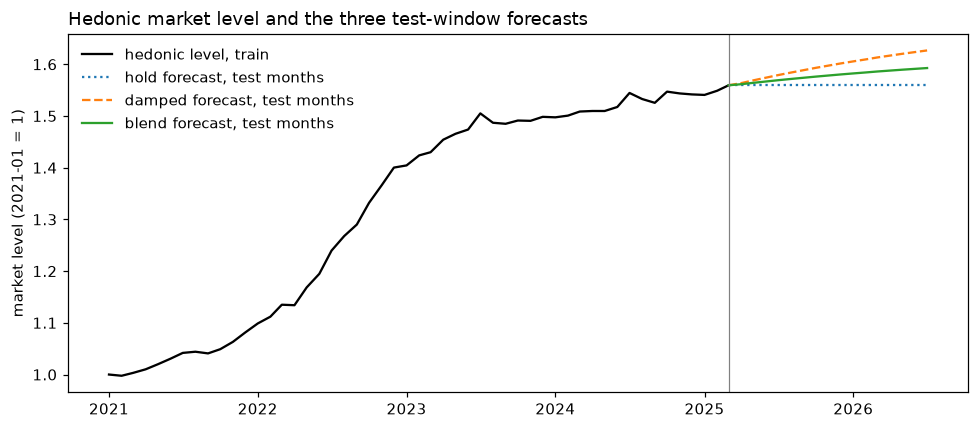

In [11]:
full_level = hedonic_level(train)
fig, ax = plt.subplots(figsize=(9, 4))
to_date = lambda idx: pd.to_datetime([f"{2021 + m // 12}-{m % 12 + 1:02d}" for m in idx])
ax.plot(to_date(full_level.index), np.exp(full_level), color="black", label="hedonic level, train")
for method, style in [("hold", ":"), ("damped", "--"), ("blend", "-")]:
    fc = forecast_level(full_level, test["MONTH_INDEX"].to_numpy(), method).loc[full_level.index.max():]
    ax.plot(to_date(fc.index), np.exp(fc), style, label=f"{method} forecast, test months")
    print(f"{method:<6} level change, 2025-03 to 2026-07: {np.exp(fc.iloc[-1] - fc.iloc[0]) - 1:+.1%}")
ax.axvline(pd.Timestamp("2025-03"), color="grey", lw=0.8)
ax.set_ylabel("market level (2021-01 = 1)")
ax.set_title("Hedonic market level and the three test-window forecasts", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **The damped trend alone is unsafe.** It gains most in the climb (786.8 → 613.0 at 2022-06) but, from the
  2022-12 origin, right as the climb ended, it keeps extrapolating and over-predicts by 533 (RMSE 870.9, the worst
  of any arm at any origin). The progress report tested only 2022-06 and 2023-11 and so never
  saw this case.
- **Hold is the same as `MONTH_INDEX`** (637.3 vs 638.6 mean). The split on its own buys nothing; any gain comes
  from the forecast.
- **Blend is best on both mean and worst case**: mean 593.6 vs 638.6, worst origin 690.0 vs 790.8. It beats
  `MONTH_INDEX` at 8 of 9 origins and loses only at 2022-12 (623.2 vs 609.4). On the four origins from 2023-03
  on, where the market is flat as it was in early 2025, it is 3 to 16 better.
- **Caveat:** the blend was added after seeing the three-origin result, and the nine origins share data. Treat
  the gain as "the blend is a safer bet than either extreme", not as a precise 45-point improvement.
- **For the test window:** the damped trend puts the level 4.3% higher by 2026-07 than at 2025-03; the blend
  puts it 2.1% higher.

Appendix C tunes on the blend.

### 5. Summary

- **The report's damped-trend result does not hold across cutoffs.** At its two cutoffs (2022-06, 2023-11) the
  damped trend is the best arm here too (613.0, 489.2), but from the 2022-12 origin it over-predicts by 533 (RMSE
  870.9), worse than the frozen `MONTH_INDEX` level (609.4).
- **A hold/damped blend is the safer level forecast:** mean RMSE 593.6 vs 638.6 for the frozen `MONTH_INDEX` and
  611.3 for the damped trend; worst origin 690.0 vs 790.8 and 870.9. It was chosen after seeing the results, so
  the size of the gain is optimistic.
- **The leaderboard disagrees.** Part 2.3 E6 adopts the `blend` level on the holdout, but its final file loses on the
  leaderboard (Part 2.3, S3 notes), so the level stays a known limitation.
- **Part 2.1's combined model and first submission use the damped trend**, as the report proposed. Switching to the
  blend has not been checked on Part 2.1's five walk-forward folds, so it remains a limitation of that model.
- **Appendices:** Part 1.6/Part 1.7 base columns + `DIST` beat Part 1.2's on these origins by 2.6 to 4.8; LightGBM ≈
  HistGradientBoosting > random forest > Ridge; tuning buys under 2 RMSE and averaging the two boosters nothing.
  The level forecast, not the model, is where the error is.

### Appendix A. Base columns: Part 1.6/Part 1.7 vs Part 1.2

| spec | numeric | categorical |
|---|---|---|
| `Part 1.6/1.7` | `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX` | `TOWN`, `FLAT_TYPE`, `FLAT_MODEL` |
| `Part 1.2` | `FLAT_TYPE_ORD`, `FLAT_AGE`, `MONTH_INDEX` | `TOWN`, `FLAT_MODEL` |
| `Part 1.2 + BLOCK_STREET` | as `Part 1.2`, plus the `BLOCK_STREET` premium | as `Part 1.2` |

Part 1.2 has no time column; `MONTH_INDEX` is added to it per Part 1.1 §7.8. Each spec is scored with and
without `DIST`, on LightGBM, across the three folds.

In [12]:
SPEC_MAIN = {"num": ["FLAT_TYPE_ORD", "FLAT_AGE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_MODEL"]}
SPEC_MAIN_BLOCK = {**SPEC_MAIN, "block_premium": True}
BASE_SPECS = {"Part 1.6/1.7": SPEC_0306, "Part 1.2": SPEC_MAIN, "Part 1.2 + BLOCK_STREET": SPEC_MAIN_BLOCK}

base_rows = []
for name, spec in BASE_SPECS.items():
    base_rows += evaluate("LightGBM", name, spec)
    base_rows += evaluate("LightGBM", f"{name} + DIST", with_dist(spec))
base_results = pd.DataFrame(base_rows)

base_table = base_results.pivot(index="spec", columns="origin", values=["rmse", "bias"])
base_table[("rmse", "mean")] = base_results.groupby("spec")["rmse"].mean()
base_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse
origin                         2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean
spec                                                                                 
Part 1.6/1.7 + DIST             738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93
Part 1.2 + BLOCK_STREET + DIST  745.32  638.07  493.61 -425.17 -204.60  -48.60 625.67
Part 1.2 + BLOCK_STREET         744.20  636.95  497.70 -420.94 -194.51  -43.90 626.28
Part 1.2 + DIST                 742.44  642.03  495.23 -422.07 -206.39  -50.43 626.57
Part 1.6/1.7                    741.86  640.13  500.61 -417.07 -194.48  -42.73 627.53
Part 1.2                        744.26  645.16  507.48 -418.42 -196.26  -50.24 632.30

In [13]:
dist_specs = [f"{name} + DIST" for name in BASE_SPECS]
best_base = base_results[base_results["spec"].isin(dist_specs)].groupby("spec")["rmse"].mean().idxmin()
print("best spec on mean RMSE:", best_base, "| used in section 4:", BEST_BASE)
print("  numeric    :", BEST_SPEC["num"] + (["BLOCK_PREMIUM"] if BEST_SPEC.get("block_premium") else []))
print("  categorical:", BEST_SPEC["cat"])

best spec on mean RMSE: Part 1.6/1.7 + DIST | used in section 4: Part 1.6/1.7 + DIST
  numeric    : ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'MONTH_INDEX', 'MAX_FLOOR', 'primary_within_2km', 'mrt_within_2km', 'primary_nearest_km', 'mrt_nearest_km', 'secondary_within_1km', 'mrt_interchange_within_1km', 'mrt_interchange_nearest_km', 'malls_within_1km', 'malls_nearest_km', 'hawker_within_1km', 'hawker_nearest_km', 'dist_to_cbd_km']
  categorical: ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL']


- **The spec matters far less than the fold.** All six specs sit within 9 of each other on mean RMSE; the market
  regime moves error by ~250 between folds.
- **`Part 1.6/1.7 + DIST` is best** on mean RMSE (623.9). On the plateau fold it ties `Part 1.2 + BLOCK_STREET + DIST`
  (493.9 vs 493.6).
- **`DIST` helps on every fold:** 741.9 → 738.1, 640.1 → 639.8, 500.6 → 493.9. The plateau-fold gain (6.7) matches
  Part 1.7's +6.79 on a similar split; on the 2022-11 fold it is almost nothing.
- **Part 1.2's column drops cost a little with trees:** 632.3 vs 627.5 without `DIST`, 626.6 vs 623.9 with it.
  Its ablation used a two-feature linear regression, where floor area and flat type are interchangeable; a tree
  uses both.
- **The `BLOCK_STREET` premium is redundant once `DIST` is in:** it improves `Part 1.2` by 6.0 on its own but adds 0.9
  on top of `DIST`. Block coordinates already carry most of what this block-only premium says. Not kept here. Part 2.3 E1 later finds that a
  block + flat type out-of-fold premium does add signal.

### Appendix B. Model comparison

`BEST_SPEC`, four model families, the three origins.

In [14]:
MODELS = ["Ridge", "Random forest", "HistGradientBoosting", "LightGBM"]
model_results = pd.DataFrame([row for model in MODELS for row in evaluate(model, BEST_BASE, BEST_SPEC)])

model_table = model_results.pivot(index="model", columns="origin", values=["rmse", "bias"])
model_table[("rmse", "mean")] = model_results.groupby("model")["rmse"].mean()
model_table[("mae", "mean")] = model_results.groupby("model")["mae"].mean()
model_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse    mae
origin               2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean   mean
model                                                                             
LightGBM              738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93 488.44
HistGradientBoosting  744.24  637.20  494.93 -425.61 -203.18  -42.01 625.46 489.87
Random forest         755.01  660.12  509.39 -441.02 -226.17  -44.03 641.51 501.46
Ridge                 665.40  629.16  661.17 -312.69  -87.43  395.87 651.91 506.70

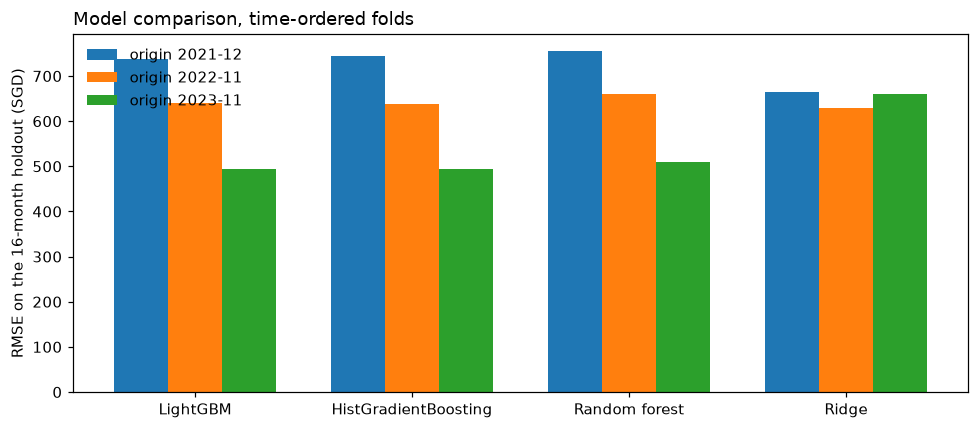

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
order = model_results.groupby("model")["rmse"].mean().sort_values().index
width = 0.25
for i, origin in enumerate(ORIGINS):
    vals = model_results[model_results["origin"] == origin].set_index("model").loc[order, "rmse"]
    ax.bar(np.arange(len(order)) + (i - 1) * width, vals, width=width, label=f"origin {origin}")
ax.set_xticks(np.arange(len(order)), order)
ax.set_ylabel("RMSE on the 16-month holdout (SGD)")
ax.set_title("Model comparison, time-ordered folds", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **LightGBM is best** on mean RMSE (623.9) and on the plateau fold (493.9). HistGradientBoosting is within 1.5,
  effectively a tie: one seed, no tuning.
- **Random forest** is worse on every fold (+17.6 on mean).
- **Ridge is best while the market grows and worst once it stops.** A linear `MONTH_INDEX` extends the trend: it
  wins the 2021-12 fold (665 vs 738, bias −313 vs −418) and loses the plateau fold by 167 (bias +396). The trees
  hold the last level instead: large under-prediction in the growth years, near-zero bias on the plateau. Same
  behaviour as Part 1.1 §7.6.
- No model choice here moves error as much as the level assumption does.

### Appendix C. Tuning and averaging

LightGBM and HistGradientBoosting tied in Appendix B, both on one untuned configuration. Each gets its default
plus 16 random draws, scored on the nine origins with the blend level. Random forest and Ridge are not tuned:
Appendix B put them 18 and 28 behind on mean RMSE.

In [16]:
LEVEL_METHOD = "blend"
PREMIUM_SPEC = premium_spec(BEST_SPEC)

# The level and the rent / level target depend only on the fold, so build them once.
level_folds = []
for origin, f, v in time_folds(train, WIDE_ORIGINS):
    s_fit, s_val = level_scales(f, v, LEVEL_METHOD)
    level_folds.append((origin, f.assign(**{TARGET: f[TARGET] / s_fit}), v, s_val))


def fold_predictions(model, params):
    return [fit_predict(model, PREMIUM_SPEC, f, v, params) * s for _, f, v, s in level_folds]


def fold_rmse(preds):
    return [score(v[TARGET].to_numpy(), p)["rmse"] for p, (_, _, v, _) in zip(preds, level_folds)]


rng = np.random.default_rng(SEED)
SEARCH = {
    "LightGBM": (LGB_PARAMS, lambda: {
        "n_estimators": int(rng.choice([300, 600, 1200])), "learning_rate": float(rng.choice([0.02, 0.05, 0.1])),
        "num_leaves": int(rng.choice([15, 31, 63, 127, 255])), "min_child_samples": int(rng.choice([10, 20, 50, 100])),
        "subsample": float(rng.choice([0.7, 0.85, 1.0])), "subsample_freq": 1,
        "colsample_bytree": float(rng.choice([0.6, 0.8, 1.0])), "reg_lambda": float(rng.choice([0.0, 1.0, 10.0])),
    }),
    "HistGradientBoosting": ({}, lambda: {
        "max_iter": int(rng.choice([300, 600, 1000])), "learning_rate": float(rng.choice([0.03, 0.05, 0.1])),
        "max_leaf_nodes": int(rng.choice([15, 31, 63, 127])), "min_samples_leaf": int(rng.choice([10, 20, 50, 100])),
        "l2_regularization": float(rng.choice([0.0, 1.0, 10.0])), "max_features": float(rng.choice([0.6, 0.8, 1.0])),
    }),
}
N_DRAWS = 16

search_rows, fold_preds = [], {}
for model, (default, draw) in SEARCH.items():
    for i, params in enumerate([default] + [draw() for _ in range(N_DRAWS)]):
        preds = fold_predictions(model, params)
        s = fold_rmse(preds)
        search_rows.append({"model": model, "draw": "default" if i == 0 else i, "rmse_mean": np.mean(s),
                            "rmse_worst": max(s), "params": params})
        fold_preds[(model, i)] = preds
search = pd.DataFrame(search_rows)
search.sort_values(["model", "rmse_mean"]).groupby("model").head(4)[["model", "draw", "rmse_mean", "rmse_worst", "params"]]

,model,draw,rmse_mean,rmse_worst,params
21,HistGradientBoosting,4,594.02,691.01,"{'max_iter': 1000, 'learning_rate': 0.1, 'max_..."
33,HistGradientBoosting,16,594.27,691.32,"{'max_iter': 300, 'learning_rate': 0.03, 'max_..."
29,HistGradientBoosting,12,594.33,691.11,"{'max_iter': 300, 'learning_rate': 0.1, 'max_l..."
28,HistGradientBoosting,11,594.35,691.19,"{'max_iter': 1000, 'learning_rate': 0.1, 'max_..."
2,LightGBM,2,591.91,689.24,"{'n_estimators': 300, 'learning_rate': 0.02, '..."
12,LightGBM,12,592.42,689.36,"{'n_estimators': 1200, 'learning_rate': 0.05, ..."
8,LightGBM,8,592.52,689.35,"{'n_estimators': 600, 'learning_rate': 0.1, 'n..."
4,LightGBM,4,592.73,689.33,"{'n_estimators': 1200, 'learning_rate': 0.1, '..."


In [17]:
best = search.loc[search.groupby("model")["rmse_mean"].idxmin()].set_index("model")
BEST_PARAMS = best["params"].to_dict()
best_draw = {m: 0 if d == "default" else d for m, d in best["draw"].items()}

per_fold = {f"{m} default": fold_rmse(fold_preds[(m, 0)]) for m in SEARCH}
per_fold.update({f"{m} tuned": fold_rmse(fold_preds[(m, best_draw[m])]) for m in SEARCH})
ensemble_preds = [(a + b) / 2 for a, b in zip(fold_preds[("LightGBM", best_draw["LightGBM"])],
                                             fold_preds[("HistGradientBoosting", best_draw["HistGradientBoosting"])])]
per_fold["average of the two tuned"] = fold_rmse(ensemble_preds)

tuning_table = pd.DataFrame(per_fold, index=WIDE_ORIGINS).T
tuning_table["mean"] = tuning_table.mean(axis=1)
tuning_table["worst"] = tuning_table[WIDE_ORIGINS].max(axis=1)
tuning_table.sort_values("mean")

,2021-12,2022-03,2022-06,2022-09,2022-12,2023-03,2023-06,2023-09,2023-11,mean,worst
LightGBM tuned,689.24,657.07,666.42,614.04,621.68,558.99,529.45,503.43,486.90,591.91,689.24
average of the two tuned,689.75,657.81,666.89,614.51,621.75,559.43,529.90,504.16,487.20,592.38,689.75
LightGBM default,690.00,657.98,666.91,615.27,623.21,561.50,531.73,506.19,489.75,593.62,690.00
HistGradientBoosting tuned,691.01,659.59,668.37,616.12,623.08,561.22,531.94,506.23,488.65,594.02,691.01
HistGradientBoosting default,691.35,659.99,669.20,617.46,624.55,563.56,533.43,508.20,491.86,595.51,691.35


- **Tuning buys under 2 RMSE:** LightGBM 593.6 → 591.9, HistGradientBoosting 595.5 → 594.0. That is the best of
  17 draws on the same folds used to pick it, so part of even that is selection luck.
- **Averaging the two does not help** (592.4, between the two). Their errors are almost the same at every
  origin: the level forecast dominates both, and it is shared.
- **Model settings are not where the error is.** The spread across origins (487 to 689) is about fifty times the
spread across the configurations in this table. The next gain, if any, is in the level.

## Part 3.2. HDB Rentals: interpreting the GNN

What the block GNN bases its rent predictions on, and whether those explanations can be trusted. This is the GNN
without block premiums; Part 3.3 explains the GNN with own-block premiums and a neighbour-premium channel, on the `damped` level, a sibling of the
model blended with LightGBM in Part 2.4, not the same model.

| | |
|---|---|
| **Model** | `hdb_rentals.gnn`, `GNN_uniform` (seeds 0, 1, 2) and the graph-free control `MLP_matched` (seed 0), damped market level, the GNN's own block table |
| **Data** | fit 2021-01 to 2023-12, explain and score 2024-01 to 2025-03 (the windows of `scripts/compare_gnn_lightgbm.py`). Epoch counts are the ones that script chose on its tuning split |
| **Explained** | 400 random holdout rentals |
| **Method** | Integrated Gradients (32 steps) from an *average flat in an average block* to the actual inputs, on each rental's exact 2-hop subgraph |
| **Reference** | LightGBM on the same inputs and target, explained with TreeSHAP |

Questions, one section each:

1. Where does one flat's predicted rent come from, in dollars?
2. Which features matter across flats, and does LightGBM agree?
3. Does the GNN use its neighbours?
4. Can these explanations be trusted?
5. Does the explainer find a neighbour effect we planted ourselves?
6. What does a GNN that learns its own edge weights learn, and do its weights agree with IG?

The explainer lives in `hdb_rentals.explain` (tests in `tests/test_explain.py`).

**Why not attribute to edges directly.** The GNN normalises edge weights per receiving block, so scaling all
of a block's edges by the same factor changes nothing: Integrated Gradients on an edge mask sums to zero by
construction. Neighbour influence is measured instead through the neighbouring blocks' *features* (IG) and by
deleting edges (`edge_mask=0`).

### Setup

In [18]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]

import torch  # before LightGBM, as the GNN scripts note
import experiment_weighted_gnns as ewg
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from hdb_rentals import gnn
from hdb_rentals.explain import SubgraphExplainer

pd.reset_option("display.float_format")  # Part 3.1 set it; the tables here quote more decimals
torch.set_num_threads(4)
OUT = ROOT / "outputs" / "11_interpretability"
(OUT / "models").mkdir(parents=True, exist_ok=True)
RETRAIN = False          # True retrains the GNNs instead of loading outputs/11_interpretability/models
N_ROWS, IG_STEPS = 400, 32
SEEDS = [0, 1, 2]
HOLD_START, HOLD_END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-04-01")

BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e2e1dc", "#fcfcfb", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110, "axes.axisbelow": True,
})

### Data, features and models

`ewg.prepare` builds the GNN's inputs. The two preprocessors are re-fitted here only to name its columns;
the assert checks they produce the same matrices.

In [19]:
rent, blocks, graph = ewg.rent, ewg.blocks, ewg.GRAPH
fit = rent[rent.RENT_APPROVAL_DATE < HOLD_START].copy()
hold = rent[(rent.RENT_APPROVAL_DATE >= HOLD_START) & (rent.RENT_APPROVAL_DATE < HOLD_END)].copy()
bundle = ewg.prepare(fit, hold)
part = bundle["parts"][1]

BLOCK_NUM, BLOCK_CAT = ewg.BLOCK_NUM, ewg.BLOCK_CAT + ["SUBZONE"]
REC_NUM, REC_CAT = ["FLOOR_AREA_SQM", "FLAT_AGE"], ["FLAT_TYPE", "FLAT_MODEL"]
bp = ewg.preprocessor(BLOCK_NUM, BLOCK_CAT).fit(blocks.iloc[np.sort(fit.block_id.unique())])
rp = ewg.preprocessor(REC_NUM, REC_CAT).fit(fit)
assert np.allclose(bp.transform(blocks), bundle["nodes"].numpy())
assert np.allclose(rp.transform(hold), part["record"].numpy())


def source_column(name, cat):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest.removeprefix("missingindicator_")
    return next(c for c in cat if rest.startswith(c + "_"))


def family(col):
    named = {"FLOOR_AREA_SQM": "Floor area", "FLAT_AGE": "Flat age", "FLAT_TYPE": "Flat type",
             "FLAT_MODEL": "Flat model", "LATITUDE": "Coordinates", "LONGITUDE": "Coordinates",
             "MAX_FLOOR": "Building height, year", "YEAR_COMPLETED": "Building height, year",
             "TOWN": "Town, area", "PLANNING_AREA": "Town, area", "SUBZONE": "Town, area"}
    if col in named:
        return named[col]
    for prefix, name in [("mrt_", "MRT access"), ("mall_", "Malls"),
                         (("school_", "primary_", "secondary_"), "Schools")]:
        if col.startswith(prefix):
            return name
    raise KeyError(col)


NODE_COLS = [source_column(n, BLOCK_CAT) for n in bp.get_feature_names_out()]
REC_COLS = [source_column(n, REC_CAT) for n in rp.get_feature_names_out()]
NODE_FAM = np.array([family(c) for c in NODE_COLS])
REC_FAM = np.array([family(c) for c in REC_COLS])
FLAT_FAMS = ["Floor area", "Flat type", "Flat model", "Flat age"]
LOC_FAMS = ["Town, area", "Coordinates", "MRT access", "Schools", "Malls", "Building height, year"]
print(f"{len(fit):,} fit rows, {len(hold):,} holdout rows; {len(REC_COLS)} record and {len(NODE_COLS)} block "
      f"input columns; {graph.n_nodes:,} blocks, {graph.n_edges:,} directed edges")

105,837 fit rows, 44,163 holdout rows; 27 record and 254 block input columns; 9,464 blocks, 87,932 directed edges


In [20]:
epochs = (pd.read_csv(ROOT / "outputs/gnn_vs_lightgbm/results.csv")
          .query("split == 'holdout' and level == 'damped' and features == 'gnn'")
          .set_index("model").epochs.astype(int))


def get_model(kind, seed):
    path = OUT / "models" / f"{kind}_seed{seed}.pt"
    if path.exists() and not RETRAIN:
        return gnn.load_model(path, graph)[0]
    n_epochs = int(epochs.get(kind, epochs["GNN_uniform"]))  # GNN_learned_edges: GNN_uniform's count
    model, _, _ = ewg.train(kind, bundle, seed, n_epochs, save_to=path, window="2021-01..2023-12")
    return model.eval()


models = {f"GNN seed {s}": get_model("GNN_uniform", s) for s in SEEDS}
models["MLP (graph off)"] = get_model("MLP_matched", 0)
gnn.seed_everything(99)  # an untrained GNN, for the randomisation check in section 4
models["GNN untrained"] = gnn.WeightedRentalGNN("GNN_uniform", bundle["nodes"].shape[1],
                                                part["record"].shape[1], graph).eval()


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))


reported = pd.read_csv(ROOT / "outputs/gnn_vs_lightgbm/summary.csv").query("level == 'damped' and features == 'gnn'")
print("holdout RMSE (compare_gnn_lightgbm reported GNN_uniform "
      f"{reported.set_index('model').holdout['GNN_uniform']}, MLP_matched {reported.set_index('model').holdout['MLP_matched']})")
for name, m in models.items():
    print(f"  {name:16s} {rmse(gnn.predict(m, bundle, part), part['y']):7.1f}")

holdout RMSE (compare_gnn_lightgbm reported GNN_uniform 489.81, MLP_matched 488.84)
  GNN seed 0         489.8
  GNN seed 1         489.6
  GNN seed 2         489.4
  MLP (graph off)    488.8
  GNN untrained      676.4


#### The explainer

For rental *i* in block *b*, the prediction depends only on blocks within two hops of *b* (two message-passing
layers). `SubgraphExplainer` cuts the trained model down to that neighbourhood and runs IG there, with the
steps batched as disjoint copies; section 4 checks the cut model against the full graph.

The baseline is the mean record of the fit rows in every block set to the mean block: with all blocks equal,
the graph has nothing to pass on. IG's attributions then sum to *f(x) − f(baseline)* (completeness). Model
output is a standardised premium: dollars = output × std × the month's market multiplier.

In [21]:
explainer = SubgraphExplainer(graph.edge_index, graph.n_nodes)
coords = blocks[["LATITUDE", "LONGITUDE"]].to_numpy()
FIT_BLOCKS = np.sort(fit.block_id.unique())
NODE_BASE = bundle["nodes"][FIT_BLOCKS].mean(0)
REC_BASE = bundle["parts"][0]["record"].mean(0)
NODES = bundle["nodes"]


@torch.no_grad()
def full_outputs(model, edge_mask=None):
    return model(NODES, part, edge_mask).numpy()


def explain(model, rows, steps=IG_STEPS):
    # Per row: record, own-block and neighbour attributions, and the subgraph vs full-graph output.
    f_full = full_outputs(model)
    out = []
    for i in rows:
        e = explainer.explain(model, NODES, part["record"][i], int(part["ids"][i]), row=i,
                              node_base=NODE_BASE, record_base=REC_BASE, steps=steps)
        out.append(dict(row=i, block=e.block, S=e.nodes, lb=e.local, rec=e.record, own=e.own, nbr=e.neighbours,
                        nbr_blocks=e.neighbour_blocks, f_full=float(f_full[i]), f_sub=e.output, base=e.baseline))
    return out


rows = np.sort(np.random.default_rng(0).choice(len(hold), N_ROWS, replace=False))
dollars = bundle["std"] * part["scale"]          # model units -> SGD, per holdout row
explanations, base_out = {}, {}
for name, m in models.items():
    explanations[name] = explain(m, rows)
    base_out[name] = explanations[name][0]["base"]
print("explained", len(rows), "rows for", len(models), "models")

explained 400 rows for 5 models


### 1. Where does one flat's rent come from?

Predicted rent = (average flat × the month's market level) + what makes this flat, its block and its
neighbours differ from average. The first bar is the average flat at the January 2021 market (the market
multiplier is 1 there); the second is how far the damped market level has moved it by the rental's month.

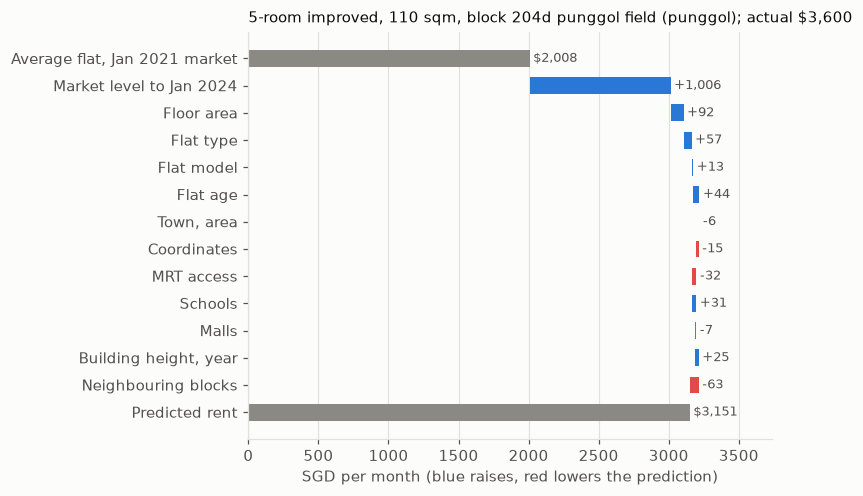

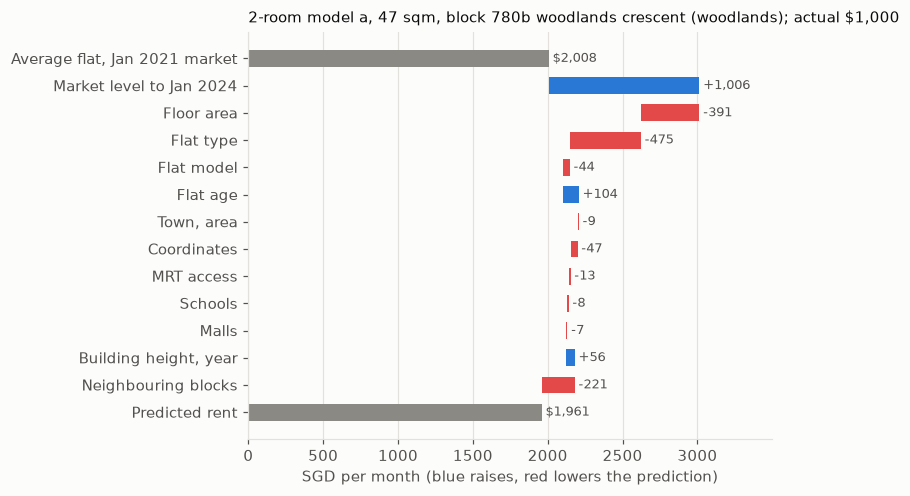

In [22]:
def family_dollars(e, name):
    i = e["row"]
    d = dollars[i]
    flat = pd.Series(e["rec"] * d).groupby(REC_FAM).sum()
    own = pd.Series(e["own"] * d).groupby(NODE_FAM).sum()
    return pd.concat([flat, own]), float(e["nbr"].sum() * d)


def waterfall(name, k):
    e = explanations[name][k]
    i = e["row"]
    scale = part["scale"][i]
    avg = (base_out[name] * bundle["std"] + bundle["mean"])
    fam, nbr = family_dollars(e, name)
    fam = fam.reindex(FLAT_FAMS + LOC_FAMS).fillna(0)
    steps = [("Average flat, Jan 2021 market", avg, "total"),
             (f"Market level to {hold.RENT_APPROVAL_DATE.iloc[i]:%b %Y}", avg * (scale - 1), "delta")]
    steps += [(f, v, "delta") for f, v in fam.items()]
    steps += [("Neighbouring blocks", nbr, "delta")]
    pred = (e["f_full"] * bundle["std"] + bundle["mean"]) * scale
    steps += [("Predicted rent", pred, "total")]
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    run, peak = 0.0, 0.0
    for y, (label, v, kind) in enumerate(steps):
        if kind == "total":
            left, width, color = 0, v, NEUTRAL
            run = v
        else:
            left, width, color = min(run, run + v), abs(v), BLUE if v >= 0 else RED
            run += v
        peak = max(peak, left + width)
        ax.barh(y, width, left=left, height=0.62, color=color)
        text = f"${v:,.0f}" if kind == "total" else f"{v:+,.0f}"
        ax.text(left + width + 25, y, text, va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(range(len(steps)), [s[0] for s in steps])
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, peak * 1.16)
    flat = hold.iloc[i]
    ax.set_title(f"{flat.FLAT_TYPE} {flat.FLAT_MODEL}, {flat.FLOOR_AREA_SQM:.0f} sqm, block {flat.BLOCK} "
                 f"{flat.STREET} ({flat.TOWN}); actual ${flat.MONTHLY_RENT:,.0f}", fontsize=9.5)
    ax.set_xlabel("SGD per month (blue raises, red lowers the prediction)")
    fig.tight_layout()
    return fig


for k in [0, 1]:
    waterfall("GNN seed 0", k).savefig(OUT / f"waterfall_{k}.png", bbox_inches="tight")
    plt.show()

### 2. Which features matter across flats, and does LightGBM agree?

Mean absolute contribution in dollars over the 400 rentals, by feature family. LightGBM is fitted to the same
target (rent ÷ market multiplier) on the same columns (block table joined to each rental) and explained with
TreeSHAP, also in dollars. LightGBM has no neighbours, so the GNN's neighbour bar has no counterpart.

LightGBM (same target and columns) holdout RMSE 484.3


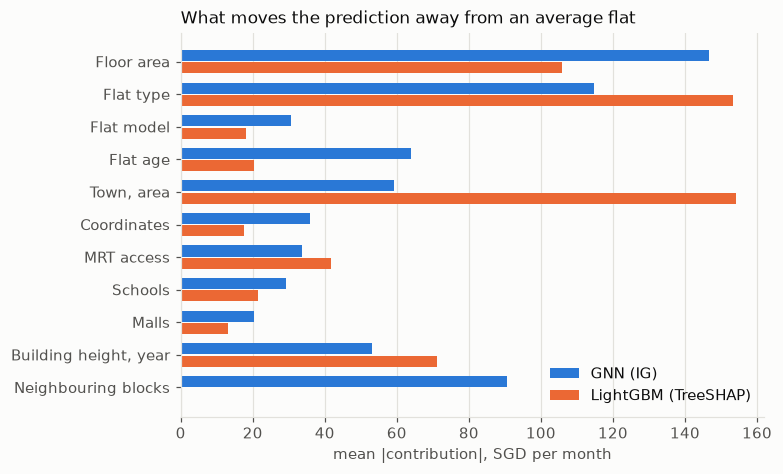

rank agreement between GNN and LightGBM over 10 shared families: Spearman 0.68


,GNN (IG),LightGBM (TreeSHAP)
Floor area,146.7,105.8
Flat type,114.8,153.3
Flat model,30.5,18.0
Flat age,64.0,20.2
"Town, area",59.2,154.3
Coordinates,36.0,17.7
MRT access,33.6,41.8
Schools,29.4,21.4
Malls,20.4,13.2
"Building height, year",53.1,71.1


In [23]:
def global_families(name):
    tab = pd.DataFrame([family_dollars(e, name)[0] for e in explanations[name]]).fillna(0)
    tab["Neighbouring blocks"] = [family_dollars(e, name)[1] for e in explanations[name]]
    return tab


LGBM_PARAMS = dict(num_leaves=63, min_child_samples=100, subsample=0.85, subsample_freq=1, colsample_bytree=0.5,
                   reg_lambda=20.0, cat_smooth=30.0, n_estimators=357, learning_rate=0.05, verbose=-1, random_state=0)


def tabular(frame):
    X = frame[REC_NUM + REC_CAT].reset_index(drop=True).join(
        blocks.loc[frame.block_id.to_numpy(), BLOCK_NUM + BLOCK_CAT].reset_index(drop=True))
    for c in REC_CAT + BLOCK_CAT:
        X[c] = pd.Categorical(X[c], categories=sorted(rent[c].dropna().unique()) if c in rent else
                              sorted(blocks[c].dropna().unique()))
    return X


fit_scale = bundle["parts"][0]["scale"]
lgbm = lgb.LGBMRegressor(**LGBM_PARAMS).fit(tabular(fit), fit.MONTHLY_RENT.to_numpy() / fit_scale)
X_hold = tabular(hold)
print(f"LightGBM (same target and columns) holdout RMSE {rmse(lgbm.predict(X_hold) * part['scale'], part['y']):.1f}")
contrib = lgbm.predict(X_hold.iloc[rows], pred_contrib=True)[:, :-1] * part["scale"][rows, None]
shap_fam = pd.DataFrame(contrib, columns=X_hold.columns).T.groupby(lambda c: family(c)).sum().T

order = FLAT_FAMS + LOC_FAMS + ["Neighbouring blocks"]
importance = pd.DataFrame({
    "GNN (IG)": global_families("GNN seed 0").abs().mean().reindex(order),
    "LightGBM (TreeSHAP)": shap_fam.abs().mean().reindex(order),
})
fig, ax = plt.subplots(figsize=(7.2, 4.4))
y = np.arange(len(order))
for j, (col, color) in enumerate(zip(importance.columns, [BLUE, ORANGE])):
    ax.barh(y + (j - 0.5) * 0.38, importance[col].fillna(0), height=0.34, color=color, label=col)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |contribution|, SGD per month")
ax.set_title("What moves the prediction away from an average flat")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "importance_gnn_vs_lgbm.png", bbox_inches="tight")
plt.show()

both = importance.dropna()
rho = spearmanr(both.iloc[:, 0], both.iloc[:, 1]).statistic
print(f"rank agreement between GNN and LightGBM over {len(both)} shared families: Spearman {rho:.2f}")
importance.round(1)

### 3. Does the GNN use its neighbours?

Three measurements on the same rentals:

- **share of attribution on neighbouring blocks** (IG, out of all |attribution|);
- **deleting every edge** (`edge_mask = 0`): how far each prediction moves;
- the **holdout RMSE** of the GNN against the identical network with the graph switched off.

The graph-free MLP must show zero on the first two; it is the check that the measurements are wired right.

In [24]:
reliance = []
for name in ["GNN seed 0", "GNN seed 1", "GNN seed 2", "MLP (graph off)"]:
    m, ex = models[name], explanations[name]
    nbr = np.array([np.abs(e["nbr"]).sum() * dollars[e["row"]] for e in ex])
    tot = np.array([(np.abs(e["rec"]).sum() + np.abs(e["own"]).sum() + np.abs(e["nbr"]).sum()) * dollars[e["row"]]
                    for e in ex])
    moved = np.abs(full_outputs(m) - full_outputs(m, torch.zeros(graph.n_edges))) * dollars
    reliance.append({"model": name, "holdout RMSE": rmse(gnn.predict(m, bundle, part), part["y"]),
                     "neighbour share of |IG|": nbr.sum() / tot.sum(),
                     "mean |Δ$| with all edges removed": moved.mean(),
                     "95th pct |Δ$|": np.percentile(moved, 95)})
reliance = pd.DataFrame(reliance).set_index("model")
reliance.style.format({"holdout RMSE": "{:.1f}", "neighbour share of |IG|": "{:.1%}",
                       "mean |Δ$| with all edges removed": "{:.1f}", "95th pct |Δ$|": "{:.1f}"})

,holdout RMSE,neighbour share of |IG|,mean |Δ$| with all edges removed,95th pct |Δ$|
model,,,,
GNN seed 0,489.8,27.1%,91.9,224.1
GNN seed 1,489.6,26.0%,114.3,266.3
GNN seed 2,489.4,30.1%,99.1,236.6
MLP (graph off),488.8,0.0%,0.0,0.0


The GNN gives neighbours a real share of the credit, yet predicts no better than the graph-free MLP. One
reading: neighbouring blocks carry much the same location information as the rental's own block, so the GNN
spreads location credit over both while the MLP puts it all on the own block. If so, the GNN's *net* location
effect (own block + neighbours) should match the MLP's own-block location effect, rental by rental.

Deleting every edge is also not a fair test of *need*: the GNN never saw a block without messages in
training, so that input is out of distribution and the dollar shift is only a rough measure of sensitivity, not a bound on the neighbours' effect.

In [25]:
def location_effects(name):
    g = global_families(name)
    return pd.DataFrame({"flat": g.reindex(columns=FLAT_FAMS).sum(axis=1),
                         "own block": g.reindex(columns=LOC_FAMS).sum(axis=1),
                         "neighbours": g["Neighbouring blocks"]})


g0, mlp = location_effects("GNN seed 0"), location_effects("MLP (graph off)")
gnn_location = g0["own block"] + g0["neighbours"]
substitution = pd.DataFrame({
    "mean |net effect| $": [g0["flat"].abs().mean(), g0["own block"].abs().mean(), g0["neighbours"].abs().mean(),
                            gnn_location.abs().mean(), mlp["flat"].abs().mean(), mlp["own block"].abs().mean()],
}, index=["GNN: flat", "GNN: own block", "GNN: neighbours", "GNN: own block + neighbours",
          "MLP: flat", "MLP: own block"])
print(f"per-rental correlation, GNN own+neighbours vs MLP own-block location effect: "
      f"{np.corrcoef(gnn_location, mlp['own block'])[0, 1]:.2f}  "
      f"(GNN own block alone vs MLP own block: {np.corrcoef(g0['own block'], mlp['own block'])[0, 1]:.2f})")
substitution.round(1)

per-rental correlation, GNN own+neighbours vs MLP own-block location effect: 0.98  (GNN own block alone vs MLP own block: 0.98)


,mean |net effect| $
GNN: flat,271.7
GNN: own block,116.7
GNN: neighbours,90.6
GNN: own block + neighbours,197.5
MLP: flat,255.2
MLP: own block,202.6


The correlation does not separate the two (own block alone also gives 0.98); the evidence for substitution is the size of the effect ($198 vs $203, against $117 for own block alone).

How far does neighbour influence reach? Each neighbour's total attribution, against its distance from the
rental's block, split by hop (1 hop = a direct edge, edges are at most 1 km long).

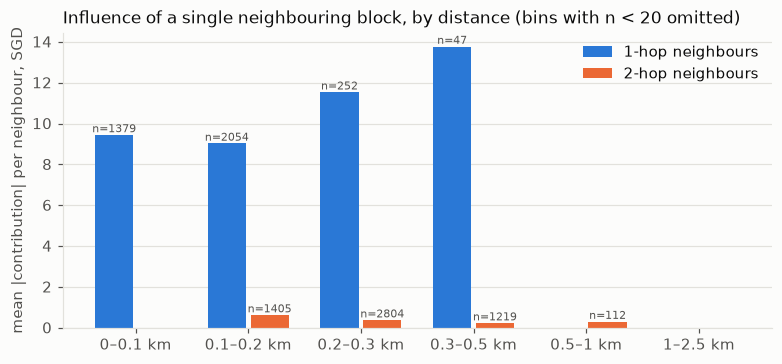

neighbours by hop: {1: {'size': 3733, 'mean': 9.41}, 2: {'size': 5546, 'mean': 0.41}}
1-hop: Spearman of |contribution| with distance 0.03


In [26]:
def haversine_km(a, b):
    p = np.radians(np.r_[a, b].reshape(2, 2))
    dlat, dlon = p[1] - p[0]
    h = np.sin(dlat / 2) ** 2 + np.cos(p[0, 0]) * np.cos(p[1, 0]) * np.sin(dlon / 2) ** 2
    return 2 * gnn.EARTH_KM * np.arcsin(np.sqrt(h))


records = []
for e in explanations["GNN seed 0"]:
    one = set(explainer.adjacency[e["block"]].indices)
    for nb, attr in zip(e["nbr_blocks"], e["nbr"].sum(1)):
        records.append(dict(km=haversine_km(coords[e["block"]], coords[nb]), hop=1 if nb in one else 2,
                            dollars=abs(attr) * dollars[e["row"]]))
reach = pd.DataFrame(records)
reach["band"] = pd.cut(reach.km, [0, 0.1, 0.2, 0.3, 0.5, 1.0, 2.5], right=False)
by_band = reach.pivot_table(index="band", columns="hop", values="dollars", aggfunc="mean", observed=False)
counts = reach.pivot_table(index="band", columns="hop", values="dollars", aggfunc="size", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(by_band))
for j, (hop, color) in enumerate(zip([1, 2], [BLUE, ORANGE])):
    vals = by_band[hop].where(counts[hop] >= 20)   # bins with fewer than 20 neighbours are not drawn
    ax.bar(x + (j - 0.5) * 0.38, vals.fillna(0), width=0.34, color=color, label=f"{hop}-hop neighbours")
    for xi, v, n in zip(x, vals, counts[hop]):
        if n >= 20:
            ax.text(xi + (j - 0.5) * 0.38, v, f"n={int(n)}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(x, [f"{b.left:g}–{b.right:g} km" for b in by_band.index])
ax.grid(axis="x", visible=False)
ax.set_ylabel("mean |contribution| per neighbour, SGD")
ax.set_title("Influence of a single neighbouring block, by distance (bins with n < 20 omitted)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "neighbour_reach.png", bbox_inches="tight")
plt.show()
print("neighbours by hop:", reach.groupby("hop").dollars.agg(["size", "mean"]).round(2).to_dict("index"))
print("1-hop: Spearman of |contribution| with distance", round(spearmanr(reach.query("hop == 1").km,
                                                                         reach.query("hop == 1").dollars).statistic, 2))

### 4. Can these explanations be trusted?

- **Exactness**: subgraph prediction = full-graph prediction; IG completeness error.
- **Fidelity**: setting the *k* most-attributed inputs to their baseline must move the prediction more than
  setting *k* random inputs. Two random pools: every input in the 2-hop subgraph (thousands, most of them
  neighbour columns that barely matter, so an easy bar), and only the rental's own record and block columns
  (a harder bar).
- **Seed stability**: the per-rental ranking of feature families should agree across the three trained seeds.
- **Randomisation**: an untrained GNN must give *different* explanations; if it agreed with the trained one,
  the explanations would reflect the inputs, not what the model learned.

In [27]:
checks = []
for name, ex in explanations.items():
    sub_err = max(abs(e["f_sub"] - e["f_full"]) for e in ex)
    comp = [abs(e["rec"].sum() + e["own"].sum() + e["nbr"].sum() - (e["f_full"] - base_out[name])) * dollars[e["row"]]
            for e in ex]
    checks.append({"model": name, "max |subgraph − full| (model units)": sub_err,
                   "median completeness error $": np.median(comp), "max completeness error $": np.max(comp)})
pd.DataFrame(checks).set_index("model").style.format("{:.2g}")

,max |subgraph − full| (model units),median completeness error $,max completeness error $
model,,,
GNN seed 0,2.4e-07,1.1,18
GNN seed 1,2.4e-07,1.2,14
GNN seed 2,2.4e-07,1.1,16
MLP (graph off),1.2e-07,1.7,43
GNN untrained,3e-08,0.16,0.92


In [28]:
@torch.no_grad()
def fidelity(name, ks=(1, 3, 5, 10, 20), draws=5, seed=0):
    rng = np.random.default_rng(seed)
    model = models[name]
    res = {k: ([], [], []) for k in ks}
    for e in explanations[name]:
        i, S, lb = e["row"], e["S"], e["lb"]
        sub = explainer.submodel(model, S)
        x, r = NODES[S].clone(), part["record"][i].clone()
        attr = np.r_[e["rec"], np.insert(e["nbr"], lb, e["own"], axis=0).ravel()]
        diff = np.r_[(r - REC_BASE).numpy(), (x - NODE_BASE).numpy().ravel()]
        pool = np.flatnonzero(np.abs(diff) > 1e-9)
        n_local = len(r) + (lb + 1) * x.shape[1]
        own_pool = pool[(pool < len(r)) | ((pool >= len(r) + lb * x.shape[1]) & (pool < n_local))]
        top = pool[np.argsort(-np.abs(attr[pool]))]
        base_flat = np.r_[REC_BASE.numpy(), NODE_BASE.expand_as(x).numpy().ravel()]
        full_flat = np.r_[r.numpy(), x.numpy().ravel()]

        def score(idx):
            v = full_flat.copy()
            v[idx] = base_flat[idx]
            rr = torch.tensor(v[:len(r)], dtype=torch.float32)
            xx = torch.tensor(v[len(r):].reshape(x.shape), dtype=torch.float32)
            return float(sub(xx, dict(ids=torch.tensor([lb]), record=rr[None]))[0])

        for k in ks:
            if k > len(pool):
                continue
            res[k][0].append(abs(score(top[:k]) - e["f_sub"]) * dollars[i])
            res[k][1].append(np.mean([abs(score(rng.choice(pool, k, replace=False)) - e["f_sub"]) * dollars[i]
                                      for _ in range(draws)]))
            if k <= len(own_pool):
                res[k][2].append(np.mean([abs(score(rng.choice(own_pool, k, replace=False)) - e["f_sub"]) * dollars[i]
                                          for _ in range(draws)]))
    return pd.DataFrame({k: {"top-k |Δ$|": np.mean(t), "random-k, whole subgraph": np.mean(rd),
                             "random-k, flat + own block": np.mean(ro)} for k, (t, rd, ro) in res.items()}).T


fid = fidelity("GNN seed 0")
fid["ratio vs flat + own block"] = fid["top-k |Δ$|"] / fid["random-k, flat + own block"]
fid.index.name = "k inputs reset"
fid.round(1)

,top-k |Δ$|,"random-k, whole subgraph","random-k, flat + own block",ratio vs flat + own block
k inputs reset,,,,
1,199.9,0.4,3.6,56.1
3,282.7,0.8,10.3,27.5
5,293.2,1.1,15.3,19.1
10,303.2,2.8,27.4,11.1
20,314.9,3.9,47.0,6.7


In [29]:
def family_matrix(name):
    return global_families(name).reindex(columns=FLAT_FAMS + LOC_FAMS + ["Neighbouring blocks"]).fillna(0).abs()


def mean_row_spearman(a, b):
    vals = [spearmanr(x, y).statistic for x, y in zip(family_matrix(a).to_numpy(), family_matrix(b).to_numpy())]
    return float(np.nanmean(vals))


pairs = [("GNN seed 0", "GNN seed 1"), ("GNN seed 0", "GNN seed 2"), ("GNN seed 1", "GNN seed 2"),
         ("GNN seed 0", "GNN untrained"), ("GNN seed 0", "MLP (graph off)")]
stability = pd.DataFrame([{"pair": f"{a} vs {b}", "mean per-rental Spearman (11 families)": mean_row_spearman(a, b)}
                          for a, b in pairs]).set_index("pair")
stability.round(2)

,mean per-rental Spearman (11 families)
pair,
GNN seed 0 vs GNN seed 1,0.79
GNN seed 0 vs GNN seed 2,0.78
GNN seed 1 vs GNN seed 2,0.77
GNN seed 0 vs GNN untrained,0.24
GNN seed 0 vs MLP (graph off),0.55


### 5. A planted neighbour effect: does the explainer find it?

The real data has no ground truth for "which neighbour mattered", so we make one. Every block gets a random
number *u* (standard normal, independent of location) as an extra block column, and the rent of a flat in
block *i* gets **+ β × (mean of *u* over *i*'s direct neighbours)**, at the month's market level. The flat's
own *u* is not used. Only a model that reads its neighbours can learn this, and we know each rental's true
dollar effect.

Three models, same epochs as above: the GNN on the planted rents, the graph-free MLP on the planted rents
(it cannot see neighbours, so it should be worse), and a control GNN that has the *u* column but real rents
(nothing to find, so the explainer should attribute about $0 to neighbours' *u*).

Two questions are separated below. *Did the model learn the effect?* Reset only the neighbours' *u* to the
baseline and read how far the prediction moves ("learned"), against the truth. *Does IG report what the model
learned?* IG on neighbours' *u* against that learned change; a slope near 1 means IG is faithful even where
the model learned only part of the truth.

In [30]:
import compare_gnn_lightgbm as cmp

BETA = 150.0                                     # SGD at the January 2021 market; keeps every rent positive
u = np.random.default_rng(1).standard_normal(graph.n_nodes)
degree = np.asarray(explainer.adjacency.sum(1)).ravel()
neighbour_mean_u = np.divide(explainer.adjacency @ u, degree, out=np.zeros_like(u), where=degree > 0)  # 1 isolated block
blocks["PLANTED_U"] = u                          # ewg.blocks: prepare reads block columns from it
PLANTED_NUM = list(BLOCK_NUM) + ["PLANTED_U"]


def plant(frame, scale):
    out = frame.copy()
    out["MONTHLY_RENT"] = out.MONTHLY_RENT + BETA * neighbour_mean_u[out.block_id.to_numpy()] * scale
    assert (out.MONTHLY_RENT > 0).all()
    return out


fit_p, hold_p = plant(fit, bundle["parts"][0]["scale"]), plant(hold, part["scale"])
bundles5 = {"planted": cmp.prepare(fit_p, [hold_p], "damped", PLANTED_NUM),
            "control": cmp.prepare(fit, [hold], "damped", PLANTED_NUM)}
names5 = ewg.preprocessor(PLANTED_NUM, BLOCK_CAT).fit(blocks.iloc[FIT_BLOCKS]).get_feature_names_out()
U = list(names5).index("num__PLANTED_U")
assert np.allclose(bundles5["control"]["nodes"][:, U].numpy(), (u - u[FIT_BLOCKS].mean()) / u[FIT_BLOCKS].std(), atol=1e-4)


def get_planted(kind, which):
    path = OUT / "models" / f"planted_{which}_{kind}_seed0.pt"
    if path.exists() and not RETRAIN:
        return gnn.load_model(path, graph)[0]
    model, _, _ = ewg.train(kind, bundles5[which], 0, int(epochs[kind]), save_to=path, planted=which, beta=BETA)
    return model.eval()


specs5 = {"GNN, planted": ("GNN_uniform", "planted"), "MLP, planted": ("MLP_matched", "planted"),
          "GNN, control": ("GNN_uniform", "control")}
models5 = {name: (get_planted(*spec), bundles5[spec[1]]) for name, spec in specs5.items()}
effect = BETA * neighbour_mean_u[hold.block_id.to_numpy()] * part["scale"]
print(f"planted effect on holdout rents: sd ${effect.std():.0f}, mean |effect| ${np.abs(effect).mean():.0f}")
pd.DataFrame({name: {"holdout RMSE on its own target": rmse(gnn.predict(m, b, b["parts"][1]), b["parts"][1]["y"])}
              for name, (m, b) in models5.items()}).T.round(1)

planted effect on holdout rents: sd $75, mean |effect| $60


,holdout RMSE on its own target
"GNN, planted",489.3
"MLP, planted",490.8
"GNN, control",489.0


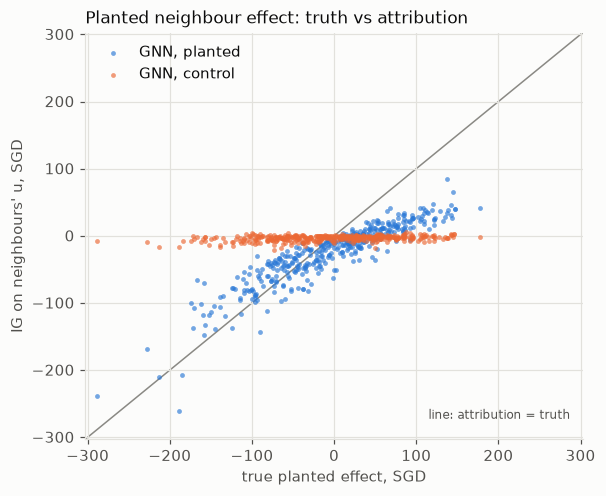

,"corr(true, IG on neighbours' u)",slope,learned/true slope,IG/learned slope,"corr(learned, IG)",per-neighbour corr,per-neighbour slope,mean |IG on neighbours' u| $,mean |IG on own u| $,mean |IG on 2-hop u| $
model,,,,,,,,,,
"GNN, planted",0.91,0.54,0.71,0.72,0.97,0.93,0.49,36.70,9.31,0.97
"GNN, control",0.35,0.02,0.01,0.70,0.85,0.48,0.02,3.78,8.45,0.17


In [31]:
def planted_attributions(name):
    model, b = models5[name]
    p, base_n, base_r = b["parts"][1], b["nodes"][FIT_BLOCKS].mean(0), b["parts"][0]["record"].mean(0)
    mu = u[FIT_BLOCKS].mean()
    per_rental, per_neighbour = [], []
    for i in rows:
        e = explainer.explain(model, b["nodes"], p["record"][i], int(p["ids"][i]), row=i,
                              node_base=base_n, record_base=base_r)
        d = b["std"] * p["scale"][i]
        hop1 = explainer.hop(e.block, e.neighbour_blocks) == 1
        # What the model actually learned: reset only the neighbours' u to the baseline, read the change.
        others = torch.from_numpy(e.neighbour_blocks)
        kept = b["nodes"][others, U].clone()
        b["nodes"][others, U] = base_n[U]
        reset = explainer.output(model, b["nodes"], p["record"][i], e.block)
        b["nodes"][others, U] = kept
        per_rental.append(dict(row=i, true=BETA * (neighbour_mean_u[e.block] - mu) * p["scale"][i],
                               learned=(e.output - reset) * d,
                               neighbours=e.neighbours[:, U].sum() * d, own=e.own[U] * d,
                               hop2=e.neighbours[~hop1, U].sum() * d))
        for j, a in zip(e.neighbour_blocks[hop1], e.neighbours[hop1, U]):
            per_neighbour.append(dict(true=BETA * (u[j] - mu) / degree[e.block] * p["scale"][i], ig=a * d))
    return pd.DataFrame(per_rental), pd.DataFrame(per_neighbour)


planted5 = {name: planted_attributions(name) for name in ["GNN, planted", "GNN, control"]}


def fit_line(x, y):
    return np.polyfit(x, y, 1)[0], np.corrcoef(x, y)[0, 1]


rows5 = []
for name, (pr, pn) in planted5.items():
    slope, corr = fit_line(pr.true, pr.neighbours)
    n_slope, n_corr = fit_line(pn.true, pn.ig)
    l_slope, l_corr = fit_line(pr.true, pr.learned)
    ig_slope, ig_corr = fit_line(pr.learned, pr.neighbours)
    rows5.append({"model": name, "corr(true, IG on neighbours' u)": corr, "slope": slope,
                  "learned/true slope": l_slope, "IG/learned slope": ig_slope, "corr(learned, IG)": ig_corr,
                  "per-neighbour corr": n_corr, "per-neighbour slope": n_slope,
                  "mean |IG on neighbours' u| $": pr.neighbours.abs().mean(),
                  "mean |IG on own u| $": pr.own.abs().mean(), "mean |IG on 2-hop u| $": pr.hop2.abs().mean()})
recovery = pd.DataFrame(rows5).set_index("model")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for (name, (pr, _)), color in zip(planted5.items(), [BLUE, ORANGE]):
    ax.scatter(pr.true, pr.neighbours, s=10, color=color, alpha=0.65, linewidths=0, label=name)
lim = np.abs(planted5["GNN, planted"][0][["true", "neighbours"]].to_numpy()).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=NEUTRAL, linewidth=1, zorder=0)
ax.text(lim * 0.95, -lim * 0.9, "line: attribution = truth", color=INK2, fontsize=8, ha="right")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("true planted effect, SGD")
ax.set_ylabel("IG on neighbours' u, SGD")
ax.set_title("Planted neighbour effect: truth vs attribution")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "planted_recovery.png", bbox_inches="tight")
plt.show()
recovery.round(2)

### 6. A GNN that learns its own edge weights

`GNN_learned_edges` weights each edge by exp(−distance / τ) × a learned function of the edge's features
(distance, age and height gaps, same subzone, same town, MRT-distance gap), with τ learned too. Its weights
summarise what it treats as a useful neighbour. Like attention, they are a diagnostic, not an explanation,
so they are set against IG below. It uses `GNN_uniform`'s epoch count (not separately tuned).

holdout RMSE 489.6 (GNN_uniform seed 0 489.8); learned tau = 0.239 km
learned feature factor (the sigmoid part, 0 to 1) by edge type:
                         size   mean    std
same_town same_subzone                     
False     False           336  0.044  0.039
          True             20  0.118  0.017
True      False          3984  0.049  0.035
          True          83592  0.134  0.061


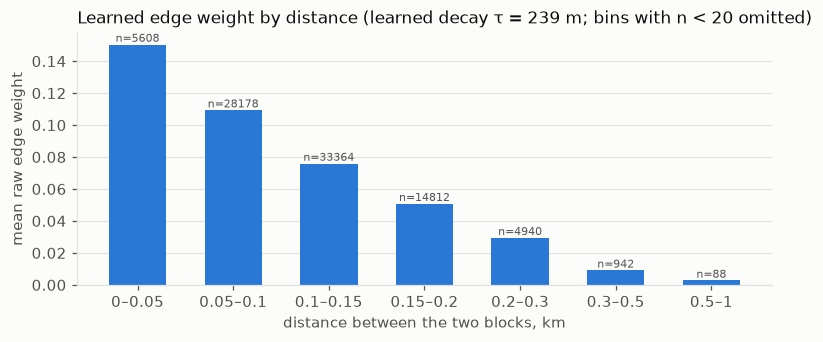

In [32]:
learned = get_model("GNN_learned_edges", 0)
with torch.no_grad():
    tau = float(torch.nn.functional.softplus(learned.log_tau).clamp(0.03, 3.0))
    raw = learned.edge_weights().numpy()
ef = graph.edge_features.numpy()
edges6 = pd.DataFrame({"km": ef[:, 0], "same_subzone": ef[:, 3] > 0.5, "same_town": ef[:, 4] > 0.5,
                       "weight": raw, "feature factor": raw / np.exp(-ef[:, 0] / tau)})
print(f"holdout RMSE {rmse(gnn.predict(learned, bundle, part), part['y']):.1f} "
      f"(GNN_uniform seed 0 {reliance.loc['GNN seed 0', 'holdout RMSE']:.1f}); learned tau = {tau:.3f} km")
print("learned feature factor (the sigmoid part, 0 to 1) by edge type:")
print(edges6.groupby(["same_town", "same_subzone"])["feature factor"].agg(["size", "mean", "std"]).round(3).to_string())

band = pd.cut(edges6.km, [0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0], right=False)
by_km = edges6.groupby(band, observed=True).weight.agg(["mean", "size"])
by_km = by_km[by_km["size"] >= 20]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
x = np.arange(len(by_km))
ax.bar(x, by_km["mean"], width=0.6, color=BLUE)
for xi, (v, n) in zip(x, by_km.to_numpy()):
    ax.text(xi, v, f"n={int(n)}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(x, [f"{b.left:g}–{b.right:g}" for b in by_km.index])
ax.grid(axis="x", visible=False)
ax.set_xlabel("distance between the two blocks, km")
ax.set_ylabel("mean raw edge weight")
ax.set_title(f"Learned edge weight by distance (learned decay τ = {tau * 1000:.0f} m; bins with n < 20 omitted)")
fig.tight_layout()
fig.savefig(OUT / "learned_edge_weights.png", bbox_inches="tight")
plt.show()

In [33]:
explanations["GNN learned edges"] = explain(learned, rows)
adj = learned.adjacency().coalesce()
weight_of = dict(zip(map(tuple, adj.indices().numpy().T), adj.values().detach().numpy()))
agree, share = [], []
for e in explanations["GNN learned edges"]:
    hop1 = explainer.hop(e["block"], e["nbr_blocks"]) == 1
    nbrs = e["nbr_blocks"][hop1]
    ig = np.abs(e["nbr"][hop1].sum(1))
    w = np.array([weight_of[(e["block"], j)] for j in nbrs])
    if len(nbrs) >= 3 and np.ptp(w) > 0:
        agree.append(spearmanr(w, ig).statistic)
    share.append(np.abs(e["nbr"]).sum() / (np.abs(e["rec"]).sum() + np.abs(e["own"]).sum() + np.abs(e["nbr"]).sum()))
learned6 = {"neighbour share of |IG|": np.mean(share), "weight-vs-IG Spearman (mean)": np.nanmean(agree),
            "weight-vs-IG Spearman (median)": np.nanmedian(agree), "rentals compared": int(np.sum(~np.isnan(agree)))}
print(f"neighbour share of |IG|: {learned6['neighbour share of |IG|']:.1%} (GNN_uniform seed 0: "
      f"{reliance.loc['GNN seed 0', 'neighbour share of |IG|']:.1%})")
print(f"per-rental Spearman between a direct neighbour's learned weight and its |IG|: mean "
      f"{learned6['weight-vs-IG Spearman (mean)']:.2f}, median {learned6['weight-vs-IG Spearman (median)']:.2f} "
      f"over {learned6['rentals compared']} rentals")

neighbour share of |IG|: 32.2% (GNN_uniform seed 0: 27.1%)
per-rental Spearman between a direct neighbour's learned weight and its |IG|: mean 0.71, median 0.86 over 400 rentals


### Summary

Numbers are from this run (400 holdout rentals, 2024-01 to 2025-03); the cell below recomputes the headline ones.

- **The explanations pass every check.** The subgraph prediction matches the full graph to 2e-7; IG's
  completeness error has a median of about $1. Resetting the 5 most-attributed inputs moves a prediction
  by $293 on average, 19× more than 5 random inputs from the rental's own record and block, and about 270×
  more than 5 random inputs from anywhere in its subgraph. Rankings agree across seeds (Spearman 0.78) and
  break for an untrained network (0.24).
- **Flat attributes come first, then location.** Floor area ($147) and flat type ($115) move predictions
  most, then flat age, town/area and building height/year. LightGBM ranks the families similarly
  (Spearman 0.68), but leans much more on town/area ($154 vs $59) and less on flat age.
- **The GNN uses its neighbours but does not need them.** Neighbouring blocks carry 26–30% of the attribution,
  and deleting all edges moves predictions by $92–114 on average (out of distribution, so only a rough measure). Yet
  the GNN is no more accurate than the same network without the graph (489.4–489.8 vs 488.8), and without premiums both
  trail LightGBM on the same inputs (484.3); equal accuracy holds for the premium models (Part 2.4). The reason is
  substitution: the GNN's location effect from own block + neighbours ($198) matches the MLP's from its own
  block alone ($203). Neighbours repeat the location signal the
  rental's own block already has.
- **Influence stops at direct neighbours.** A 1-hop neighbour contributes about $9; a 2-hop neighbour
  $0.4. Within the 1 km edge radius it does not fall off with distance (Spearman 0.03), but almost all edges
  are under 300 m.

- **The explainer finds a planted neighbour effect, but understates its size.** With a known effect of
  +$150 × the mean of a random block value over direct neighbours (sd $75 on holdout rents), the GNN beats the
  graph-free MLP on the planted target (489.3 vs 490.8). Two separate answers:
  - *What the model learned*: resetting only the neighbours' value moves predictions by 71% of the true
    effect.
  - *What IG reports*: IG on the neighbours' value matches that learned change in ranking (correlation 0.97;
    0.91 against the truth per rental, 0.93 per neighbour) but at about 72% of its size, and less on the
    positive side than the negative.

  The control model (same column, nothing planted) gets one tenth of the attribution ($3.80 vs $36.70), and
  2-hop neighbours get almost none ($1). So IG can be trusted for *which* neighbours and features matter and
  in which direction, and its dollar amounts are a lower bound for neighbour effects.
- **A GNN that learns its edge weights learns a 240 m neighbourhood.** Its learned decay is τ = 239 m. Edges
  inside the same subzone get about three times the weight of edges that cross a town boundary (feature
  factor 0.134 vs 0.044). Accuracy is unchanged (489.6). Its neighbours carry 32% of the attribution, and a
  direct neighbour's learned weight ranks neighbours much as IG does (per-rental Spearman: median 0.86,
  mean 0.71). Its weights are a fair summary for this model, though a diagnostic, not a proof.

The neighbour-premium GNN (`scripts/gnn_neighbour_premiums.py`), where neighbours carry past
rents the block may lack, is explained in Part 3.3.

In [34]:
summary = {
    "GNN seed 0 holdout RMSE": reliance.loc["GNN seed 0", "holdout RMSE"],
    "MLP holdout RMSE": reliance.loc["MLP (graph off)", "holdout RMSE"],
    "neighbour share of |IG| (seeds 0-2)": reliance.loc[["GNN seed 0", "GNN seed 1", "GNN seed 2"], "neighbour share of |IG|"].round(3).tolist(),
    "mean |Δ$| all edges removed (seed 0)": reliance.loc["GNN seed 0", "mean |Δ$| with all edges removed"],
    "GNN vs LightGBM family rank Spearman": rho,
    "fidelity ratio top/random (flat + own block) at k=5": fid.loc[5, "ratio vs flat + own block"],
    "seed stability (mean of 3 pairs)": stability.iloc[:3, 0].mean(),
    "trained vs untrained": stability.iloc[3, 0],
}
pd.Series(summary)

GNN seed 0 holdout RMSE                                          489.770414
MLP holdout RMSE                                                 488.822632
neighbour share of |IG| (seeds 0-2)                    [0.271, 0.26, 0.301]
mean |Δ$| all edges removed (seed 0)                              91.858981
GNN vs LightGBM family rank Spearman                               0.684848
fidelity ratio top/random (flat + own block) at k=5               19.143145
seed stability (mean of 3 pairs)                                   0.781167
trained vs untrained                                               0.241159
dtype: object

## Part 3.3. HDB Rentals: interpreting the neighbour-premium GNN

`scripts/gnn_neighbour_premiums.py` gives each rental two kinds of past-rent information:

- **its own block's premium**, as row inputs (Part 2.3's E1: block and block + flat type premiums of
  relative rent and the block + flat type row count; out-of-fold for fit rows);
- **its direct neighbours' premiums**, through a one-hop channel read after message passing (never its own).

On the holdout the channel changes overall RMSE by nothing (482.06 vs 482.04 without it), and helps a little
only for blocks with almost no past rentals of that flat type. This part asks *why*, with the
explainer, checks and conventions of Part 3.2:

1. Does the model lean on neighbours' premiums more when its own block has little history?
2. What happens to predictions if the neighbours' premiums are replaced by an average block's?
3. Do the channel's gates (a diagnostic) tell the same story as the attributions?
4. Are the explanations exact and complete for this model?

| | |
|---|---|
| **Models** | `NeighbourPremiumGNN` as `GNN_uniform` and as `MLP_matched` (message passing off, premium channel on), seed 0 |
| **Data** | fit 2021-01 to 2023-12, scored 2024-01 to 2025-03; epochs from that script's tuning split |
| **Explained** | 120 random holdout rentals per history bucket (0, 1-2, 3-5, 6-10, >10 earlier fit rentals of the same block + flat type) |
| **Baseline** | mean fit record, mean fit block, mean fit-block premium |

### Setup

In [35]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]

import gnn_neighbour_premiums as gnp  # imports torch before LightGBM
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from hdb_rentals.explain import SubgraphExplainer

gpb, cmp, ewg = gnp.gpb, gnp.cmp, gnp.ewg
torch.set_num_threads(4)
OUT = ROOT / "outputs" / "12_interpretability_premiums"
(OUT / "models").mkdir(parents=True, exist_ok=True)
RETRAIN = False          # True retrains instead of loading outputs/12_interpretability_premiums/models
PER_BUCKET, IG_STEPS = 120, 32
BUCKETS = gnp.BUCKETS

BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK2, GRID, SURFACE, NEUTRAL = "#0b0b0b", "#52514e", "#e2e1dc", "#fcfcfb", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 11, "font.size": 9.5, "figure.dpi": 110, "axes.axisbelow": True,
})

### Data and models

Built exactly as `gnn_neighbour_premiums.main` builds its holdout split.

In [36]:
hdb = cmp.part23_block_table()
tr, frames = gpb.part23_premium_frames(hdb)
fit_rows, val_rows, node_rows = frames["holdout"]
rent, blocks, graph = ewg.rent, ewg.blocks, ewg.GRAPH
d = rent.RENT_APPROVAL_DATE
prem_rows = pd.concat([fit_rows, val_rows])
fit = gpb.with_premiums(rent[d < cmp.HOLD_START], prem_rows)
hold = gpb.with_premiums(rent[(d >= cmp.HOLD_START) & (d < cmp.HOLD_END)], prem_rows)
hold["history"] = prem_rows.set_index("row_id")["BLOCK_FT_N"].reindex(hold.row_id).to_numpy()
hold["bucket"] = pd.cut(hold.history, BUCKETS[0], labels=BUCKETS[1])

x = blocks[cmp.KEY].merge(node_rows, on=cmp.KEY, how="left", validate="m:1")[gpb.NODE_PREM] \
    .fillna({"NODE_BLOCK_PREM": 1.0, "NODE_LOG_N": 0.0}).to_numpy(float)
x[:, 0] = np.log(x[:, 0])
PREMIUMS = torch.tensor((x - x.mean(0)) / x.std(0), dtype=torch.float32)
bundle = cmp.prepare(fit, [hold], "damped", list(ewg.BLOCK_NUM), gpb.PREM)
bundle["node_premiums"] = PREMIUMS
part, NODES = bundle["parts"][1], bundle["nodes"]

BLOCK_NUM, BLOCK_CAT = list(ewg.BLOCK_NUM), ewg.BLOCK_CAT + ["SUBZONE"]
REC_NUM, REC_CAT = ["FLOOR_AREA_SQM", "FLAT_AGE", *gpb.PREM], ["FLAT_TYPE", "FLAT_MODEL"]
FIT_BLOCKS = np.sort(fit.block_id.unique())
bp = ewg.preprocessor(BLOCK_NUM, BLOCK_CAT).fit(blocks.iloc[FIT_BLOCKS])
rp = ewg.preprocessor(REC_NUM, REC_CAT).fit(fit)
assert np.allclose(bp.transform(blocks), NODES.numpy()) and np.allclose(rp.transform(hold), part["record"].numpy())


def source_column(name, cat):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest.removeprefix("missingindicator_")
    return next(c for c in cat if rest.startswith(c + "_"))


REC_COLS = np.array([source_column(n, REC_CAT) for n in rp.get_feature_names_out()])
OWN_PREMIUM = np.isin(REC_COLS, gpb.PREM)
print(f"{len(fit):,} fit and {len(hold):,} holdout rows; record columns: {len(REC_COLS)} "
      f"({OWN_PREMIUM.sum()} own-block premium); block columns: {NODES.shape[1]}; neighbour premium columns: "
      f"{PREMIUMS.shape[1]} ({', '.join(gpb.NODE_PREM)})")
print("holdout rows per history bucket:", hold.bucket.value_counts().reindex(BUCKETS[1]).to_dict())

105,837 fit and 44,163 holdout rows; record columns: 30 (3 own-block premium); block columns: 254; neighbour premium columns: 2 (NODE_BLOCK_PREM, NODE_LOG_N)
holdout rows per history bucket: {'0': 635, '1-2': 3167, '3-5': 7100, '6-10': 11305, '>10': 21956}


In [37]:
reported = pd.read_csv(ROOT / "outputs/gnn_neighbour_premiums/results.csv").query("split == 'holdout' and premiums == 'row+nbr'")
epochs = reported.dropna(subset=["epochs"]).set_index("model").epochs.astype(int)


def get_model(kind):
    path = OUT / "models" / f"premiums_{kind}_seed0.pt"
    model = gnp.NeighbourPremiumGNN(kind, NODES.shape[1], part["record"].shape[1], PREMIUMS)
    if path.exists() and not RETRAIN:
        missing, unexpected = model.load_state_dict(torch.load(path, weights_only=True), strict=False)
        assert not unexpected and set(missing) <= {n for n, _ in model.named_buffers()}
        return model.eval()
    fitted, _, _ = gnp.train(kind, bundle, 0, int(epochs[kind]))
    torch.save(dict(fitted.named_parameters()), path)  # parameters only; graph buffers come from the class
    return fitted.eval()


models = {"GNN": get_model("GNN_uniform"), "MLP (graph off)": get_model("MLP_matched")}


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))


preds = {name: ewg.predict(m, bundle, part) for name, m in models.items()}
check = pd.DataFrame({name: {"holdout RMSE here": rmse(p, part["y"]),
                             "reported": reported.set_index("model").rmse[kind]}
                      for (name, p), kind in zip(preds.items(), ["GNN_uniform", "MLP_matched"])}).T
by_bucket = pd.DataFrame({name: pd.Series((p - part["y"]) ** 2).groupby(hold.bucket.to_numpy(), observed=False).mean() ** 0.5
                          for name, p in preds.items()}).reindex(BUCKETS[1])
by_bucket["rows"] = hold.bucket.value_counts().reindex(BUCKETS[1])
display(check.round(2))
by_bucket.round(1)

,holdout RMSE here,reported
GNN,482.09,482.06
MLP (graph off),482.14,482.09


,GNN,MLP (graph off),rows
0,575.9,576.6,635
1-2,507.5,507.0,3167
3-5,500.7,500.5,7100
6-10,485.5,485.5,11305
>10,467.2,467.5,21956


### 1. Own premium vs neighbours' premiums, by how much history the block has

Mean absolute contribution in dollars per rental, by input group. If the channel fills gaps, neighbours'
premiums should matter more where the block has no or few past rentals of that flat type, and the block's own
premium should take over as its history grows.

In [38]:
explainer = SubgraphExplainer(graph.edge_index, graph.n_nodes)
NODE_BASE = NODES[FIT_BLOCKS].mean(0)
REC_BASE = bundle["parts"][0]["record"].mean(0)
PREM_BASE = PREMIUMS[FIT_BLOCKS].mean(0)
dollars = bundle["std"] * part["scale"]

rng = np.random.default_rng(0)
rows = np.sort(np.concatenate([rng.choice(np.flatnonzero(hold.bucket.to_numpy() == b), PER_BUCKET, replace=False)
                               for b in BUCKETS[1]]))


@torch.no_grad()
def full_outputs(model):
    return model(NODES, part).numpy()


def explain(model):
    f_full = full_outputs(model)
    out = []
    for i in rows:
        e = explainer.explain(model, NODES, part["record"][i], int(part["ids"][i]), row=i, steps=IG_STEPS,
                              node_base=NODE_BASE, record_base=REC_BASE, extra={"premiums": (PREMIUMS, PREM_BASE)})
        dd = dollars[i]
        prem = e.extra["premiums"]
        out.append(dict(row=i, bucket=hold.bucket.iloc[i],
                        flat=np.abs(e.record[~OWN_PREMIUM].sum()) * dd,
                        own_premium=np.abs(e.record[OWN_PREMIUM].sum()) * dd,
                        own_location=np.abs(e.own.sum()) * dd,
                        neighbour_features=np.abs(e.neighbours.sum()) * dd,
                        neighbour_premiums=np.abs(np.delete(prem, e.local, axis=0).sum()) * dd,
                        own_premium_via_channel=np.abs(prem[e.local]).sum(),
                        signed_neighbour_premiums=np.delete(prem, e.local, axis=0).sum() * dd,
                        total=e.total(), gap=e.output - e.baseline, sub=e.output, full=float(f_full[i]),
                        completeness_dollars=abs(e.total() - (e.output - e.baseline)) * dd))
    return pd.DataFrame(out)


attr = {name: explain(m) for name, m in models.items()}
GROUPS = {"flat": "Flat attributes", "own_premium": "Own block's premium", "own_location": "Own block's location",
          "neighbour_features": "Neighbours' features", "neighbour_premiums": "Neighbours' premiums"}
tables = {name: a.groupby("bucket", observed=False)[list(GROUPS)].mean().rename(columns=GROUPS).reindex(BUCKETS[1])
          for name, a in attr.items()}
for name, t in tables.items():
    t["neighbours' premiums / own premium"] = t["Neighbours' premiums"] / t["Own block's premium"]
    print(name)
    display(t.round(1))

GNN


,Flat attributes,Own block's premium,Own block's location,Neighbours' features,Neighbours' premiums,neighbours' premiums / own premium
bucket,,,,,,
0,324.1,68.5,133.0,29.8,63.4,0.9
1-2,288.3,126.0,107.5,24.8,40.3,0.3
3-5,255.9,118.6,81.7,24.0,38.1,0.3
6-10,232.1,108.9,83.3,22.0,39.3,0.4
>10,285.5,82.5,87.8,24.6,48.0,0.6


MLP (graph off)


,Flat attributes,Own block's premium,Own block's location,Neighbours' features,Neighbours' premiums,neighbours' premiums / own premium
bucket,,,,,,
0,313.2,66.4,179.1,0.0,72.9,1.1
1-2,281.8,123.0,145.1,0.0,41.9,0.3
3-5,249.9,114.6,106.7,0.0,37.3,0.3
6-10,227.9,104.6,111.2,0.0,38.6,0.4
>10,278.9,77.4,117.5,0.0,49.7,0.6


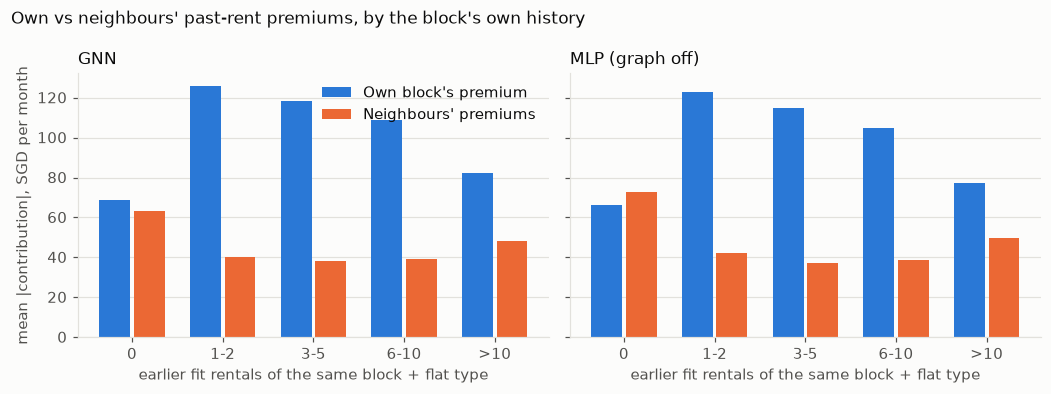

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharey=True)
x = np.arange(len(BUCKETS[1]))
for ax, (name, t) in zip(axes, tables.items()):
    for j, (col, color) in enumerate([("Own block's premium", BLUE), ("Neighbours' premiums", ORANGE)]):
        ax.bar(x + (j - 0.5) * 0.38, t[col], width=0.34, color=color, label=col)
    ax.set_xticks(x, BUCKETS[1])
    ax.set_xlabel("earlier fit rentals of the same block + flat type")
    ax.grid(axis="x", visible=False)
    ax.set_title(name)
axes[0].set_ylabel("mean |contribution|, SGD per month")
axes[0].legend(frameon=False)
fig.suptitle("Own vs neighbours' past-rent premiums, by the block's own history", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "premiums_by_history.png", bbox_inches="tight")
plt.show()

### 2. Replacing the neighbours' premiums with an average block's

Every block's channel input is set to the mean fit-block premium (an average neighbourhood, inside the range
the model was trained on, unlike deleting edges). The change in each prediction, by history bucket.

In [40]:
@torch.no_grad()
def without_neighbour_premiums(model):
    kept = model.premiums.clone()
    model.premiums = PREM_BASE.expand_as(kept).clone()
    out = model(NODES, part).numpy()
    model.premiums = kept
    return out


replace = []
for name, m in models.items():
    delta = (full_outputs(m) - without_neighbour_premiums(m)) * dollars
    g = pd.Series(np.abs(delta)).groupby(hold.bucket.to_numpy(), observed=False)
    replace.append(pd.DataFrame({"model": name, "bucket": BUCKETS[1],
                                 "mean |Δ$|": g.mean().reindex(BUCKETS[1]).to_numpy(),
                                 "95th pct |Δ$|": g.quantile(0.95).reindex(BUCKETS[1]).to_numpy()}))
replace = pd.concat(replace).pivot(index="bucket", columns="model").reindex(BUCKETS[1])
replace.round(1)

mean |Δ$|                 95th pct |Δ$|                
model        GNN MLP (graph off)           GNN MLP (graph off)
bucket                                                        
0           74.6            85.8         171.3           179.9
1-2         48.5            50.9         166.2           166.2
3-5         38.2            38.6         156.3           147.8
6-10        39.4            39.2         169.2           156.6
>10         50.9            51.8         194.2           175.5

### 3. The channel's gates (diagnostic only)

The channel adds `gate × message` to each block's embedding; `gnn_neighbour_premiums.py` reported that the mean
gate falls as a block's history grows. Gates are like attention weights: they show how much is let through,
not how much it changes the prediction, so they are set against the attributions from section 1.

In [41]:
gate_rows = []
for name, m in models.items():
    full_outputs(m)                                   # sets m.last_premium_gate for every block
    g = m.last_premium_gate.mean(1).numpy()[part["ids"].numpy()]
    s = pd.Series(g).groupby(hold.bucket.to_numpy(), observed=False).mean().reindex(BUCKETS[1])
    gate_rows.append(pd.DataFrame({"model": name, "bucket": BUCKETS[1], "mean gate": s.to_numpy(),
                                   "mean |IG| on neighbours' premiums $": tables[name]["Neighbours' premiums"].to_numpy()}))
gates = pd.concat(gate_rows).pivot(index="bucket", columns="model").reindex(BUCKETS[1])
gates.round(3)

mean gate                 mean |IG| on neighbours' premiums $                
model        GNN MLP (graph off)                                 GNN MLP (graph off)
bucket                                                                              
0          0.145           0.141                              63.410          72.947
1-2        0.136           0.133                              40.295          41.939
3-5        0.132           0.129                              38.110          37.297
6-10       0.129           0.127                              39.269          38.601
>10        0.121           0.119                              48.028          49.651

### 4. Checks

In [42]:
checks = pd.DataFrame({name: {"max |subgraph − full| (model units)": (a["sub"] - a["full"]).abs().max(),
                              "median completeness error $": a.completeness_dollars.median(),
                              "max completeness error $": a.completeness_dollars.max(),
                              "max |IG| on own premium via channel": a.own_premium_via_channel.max(),
                              "max |IG| on neighbours' features": a.neighbour_features.max()}
                       for name, a in attr.items()}).T
checks.style.format("{:.2g}")

,max |subgraph − full| (model units),median completeness error $,max completeness error $,max |IG| on own premium via channel,max |IG| on neighbours' features
GNN,2.4e-07,0.67,9.7,0,3e+02
MLP (graph off),2.4e-07,1,12,0,0


### Summary

From this run: 600 holdout rentals, 120 per history bucket.

- **The explanations are exact and respect the design.** The subgraph matches the full graph to 2e-7, and the
  median completeness error is about $1 or less. A block's own premium never comes back through the channel
  (attribution exactly 0), and the graph-free version gives neighbours' features exactly 0.
- **The model leans on neighbours' premiums where its own block has no history.**
  - With no earlier fit rentals of that block + flat type, neighbours' premiums move a prediction by $63 on
    average, about as much as the block's own premium ($68, which then falls back to a block-wide prior).
  - With 1 to 10 earlier rentals, the block's own premium dominates ($109–126 vs $38–40).
  - Replacing the neighbours' premiums with an average block's shows the same picture: $75 at zero history,
    $38–51 elsewhere.
- **That only pays off in the thin slice.** By-bucket RMSE improves only for thin history (this run: 0 rentals
  575.9 and 1-2 rentals 507.5, against 577.9 and 508.9 for the same GNN without the channel in `gnn_neighbour_premiums.py`). Zero-history rows are
  635 of 44,163 (1.44%), and 0.77% of test rows (Part 2.4), which is why the channel
  cannot move overall RMSE. Elsewhere the channel shifts predictions by about $40 without making them more accurate,
  as in Part 3.2, where neighbours' features repeat what the block already has.
- **The pattern is in the channel, not in message passing.** The graph-free MLP with the same channel shows
  the same pattern (zero-history bucket: $73 from neighbours' premiums vs $66 own).
- **The gates and the attributions disagree for well-documented blocks.** The mean gate falls steadily with
  history (0.145 to 0.121). The attribution to neighbours' premiums is U-shaped: $63 at zero history, $38 in
  the middle, back up to $48 above 10. Attention-style weights are known to be unreliable as explanations: a lower gate
  does not mean the input matters less, so gates should not be reported as explanations.